# Analyse métier - Étoile Commandes

**Table Druid :** fact_order  
**Grain :** Une ligne par commande

Ce notebook exécute cinquante visuels depuis la table Druid dénormalisée indiquée ci-dessus. La première cellule détecte une connexion accessible depuis le noyau Python : `http://127.0.0.1:25019/druid/v2/sql` sur l’hôte ou `http://druid-router:8888/druid/v2/sql` dans Docker. Pour imposer une URL, définir `DRUID_SQL_URL_OVERRIDE` ou la variable d’environnement `DRUID_SQL_URL`.

**Limite du modèle :** Cette étoile protège les montants du double comptage entre articles et paiements. Un panier moyen doit être recalculé par somme des montants / nombre de commandes. Les dates de jalons sont des dimensions à rôles multiples; seules certaines dates peuvent être présentes selon le statut.

**Source du modèle :** [20_build_ebrasil_warehouse.py](https://github.com/rbizoi/FormationBigDataBI/blob/master/spark/jobs/20_build_ebrasil_warehouse.py), blob GitHub `8b553b3970eb8f3f5804ac0072569cfade518c57`. Le script produit les six tables dénormalisées ; `docker/ebrasil-druid/ingest.py` les ingère sous les mêmes noms, sans rollup. Au démarrage, le notebook contrôle les six tables et les colonnes utilisées par ses graphiques via `INFORMATION_SCHEMA.COLUMNS`, ainsi que la présence de lignes dans sa table. Aucune donnée de démonstration ni dimension séparée n’est utilisée. La compatibilité du schéma est contrôlée ; la provenance des lignes dépend de l’initialisation eBrasil du dépôt.


In [1]:
import os
import socket
import warnings
from pathlib import Path
from urllib.parse import urlsplit, urlunsplit
import requests
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# None : sélection automatique depuis le noyau Python, indépendamment du navigateur.
# Pour imposer une adresse, renseigner ceci ou la variable d'environnement DRUID_SQL_URL.
DRUID_SQL_URL_OVERRIDE = None
HOST_SQL_URL = "http://127.0.0.1:25019/druid/v2/sql"
DOCKER_SQL_URL = "http://druid-router:8888/druid/v2/sql"
TABLE = "fact_order"
MODEL_TABLES = ["fact_logistics","fact_order","fact_order_item","fact_payment","fact_review","mart_customer_rfm"]
REQUIRED_COLUMNS = ["approved_date_calendar_date","customer_city","customer_state","customer_zip_code","delivered_date_calendar_date","estimated_delivery_date_calendar_date","freight_amount","item_count","order_id","payment_amount","payment_gap","product_amount","product_count","purchase_date_calendar_date","purchase_date_quarter","purchase_date_weekday","purchase_date_year","purchase_time_day_part","purchase_time_hour","seller_count","shipped_date_calendar_date","status"]
MODEL_SOURCE = "https://github.com/rbizoi/FormationBigDataBI/blob/master/spark/jobs/20_build_ebrasil_warehouse.py"
MODEL_SOURCE_BLOB_SHA = "8b553b3970eb8f3f5804ac0072569cfade518c57"

def normalize_sql_url(value):
    parsed = urlsplit(value.strip())
    if parsed.scheme not in ("http", "https") or not parsed.hostname:
        raise ValueError("DRUID_SQL_URL doit être une URL HTTP complète, sans syntaxe Markdown.")
    if parsed.username or parsed.password or parsed.query or parsed.fragment:
        raise ValueError("Ne pas inclure d'identifiants, de paramètres ou de fragment dans DRUID_SQL_URL.")
    netloc = parsed.netloc
    if parsed.hostname == "druid-router" and parsed.port == 25019:
        warnings.warn("Port corrigé : druid-router utilise 8888 ; 25019 est le port de l'hôte.")
        netloc = "druid-router:8888"
    if parsed.hostname in ("localhost", "127.0.0.1") and parsed.port == 8888:
        warnings.warn("Port hôte corrigé selon le dépôt : 127.0.0.1:25019.")
        netloc = "127.0.0.1:25019"
    path = parsed.path.rstrip("/") or "/druid/v2/sql"
    if path != "/druid/v2/sql":
        raise ValueError("Le point d'accès attendu est /druid/v2/sql.")
    return urlunsplit((parsed.scheme, netloc, path, "", ""))

def select_druid_url():
    explicit = DRUID_SQL_URL_OVERRIDE or os.getenv("DRUID_SQL_URL", "").strip()
    try:
        socket.getaddrinfo("druid-router", 8888)
        docker_dns = True
    except OSError:
        docker_dns = False
    in_docker = Path("/.dockerenv").exists() or docker_dns
    candidates = [DOCKER_SQL_URL, HOST_SQL_URL] if in_docker else [HOST_SQL_URL, DOCKER_SQL_URL]
    if explicit:
        candidates = [normalize_sql_url(explicit)]
    errors = []
    for url in candidates:
        try:
            response = requests.post(url, json={"query": "SELECT 1 AS connexion_ok", "resultFormat": "object"}, timeout=(3, 8))
            response.raise_for_status()
            result = response.json()
            if not isinstance(result, list) or not result or result[0].get("connexion_ok") != 1:
                raise ValueError("Ce service ne répond pas comme Druid SQL.")
            return url
        except (requests.RequestException, ValueError) as exc:
            errors.append(f"{url} : {exc}")
    raise ConnectionError(
        "Connexion Druid impossible depuis ce noyau Python.\nWindows : " + HOST_SQL_URL +
        "\nDocker du dépôt : " + DOCKER_SQL_URL +
        "\nVérifier druid-router et le réseau Docker. Corriger ou supprimer la variable DRUID_SQL_URL si elle est définie.\n" +
        "\n".join(errors)
    )

DRUID_SQL_URL = select_druid_url()

def druid_sql(sql):
    try:
        response = requests.post(DRUID_SQL_URL,
            json={"query": sql, "resultFormat": "object",
                  "context": {"sqlTimeZone": "UTC", "useApproximateCountDistinct": False}}, timeout=(5, 120))
    except requests.RequestException as exc:
        raise ConnectionError(f"Druid inaccessible à {DRUID_SQL_URL}. Relancer la cellule de connexion.") from exc
    if not response.ok:
        raise RuntimeError(f"Druid SQL HTTP {response.status_code}\nSQL : {sql}\n{response.text[:3000]}")
    data = response.json()
    if not isinstance(data, list):
        raise ValueError("Druid doit renvoyer une liste d'objets JSON.")
    return pd.DataFrame(data)

# Toutes les données analysées proviennent des tables dénormalisées exposées par Druid.
model_names = ", ".join("'" + name + "'" for name in MODEL_TABLES)
schema = druid_sql(
    'SELECT TABLE_NAME AS "table_name", COLUMN_NAME AS "column_name", DATA_TYPE AS "data_type" '
    "FROM INFORMATION_SCHEMA.COLUMNS WHERE TABLE_SCHEMA = 'druid' AND TABLE_NAME IN (" + model_names + ")"
)
if schema.empty:
    raise RuntimeError("Aucune étoile eBrasil dans Druid : exécuter l'initialisation du dépôt.")
missing_tables = set(MODEL_TABLES) - set(schema["table_name"])
if missing_tables:
    raise RuntimeError("Tables Druid manquantes : " + ", ".join(sorted(missing_tables)))
present_columns = set(schema.loc[schema["table_name"] == TABLE, "column_name"])
missing_columns = set(REQUIRED_COLUMNS) - present_columns
if missing_columns:
    raise RuntimeError(f"Schéma incompatible pour {TABLE}. Colonnes dénormalisées manquantes : " +
        ", ".join(sorted(missing_columns)) + ". Reconstruire avec 20_build_ebrasil_warehouse.py puis réingérer dans Druid.")
row_count = int(druid_sql(f'SELECT COUNT(*) AS lignes FROM "{TABLE}"').iloc[0]["lignes"])
if row_count == 0:
    raise RuntimeError(f"La table Druid {TABLE} est vide.")
print("Druid SQL :", DRUID_SQL_URL)
print(f"Table : {TABLE} | {row_count:,} lignes | {len(REQUIRED_COLUMNS)} colonnes contrôlées")
print("Source du modèle :", MODEL_SOURCE)
display(schema.loc[schema["table_name"] == TABLE].reset_index(drop=True))


Druid SQL : http://127.0.0.1:25019/druid/v2/sql
Table : fact_order | 99,441 lignes | 22 colonnes contrôlées
Source du modèle : https://github.com/rbizoi/FormationBigDataBI/blob/master/spark/jobs/20_build_ebrasil_warehouse.py


,table_name,column_name,data_type
0,fact_order,__time,TIMESTAMP
1,fact_order,order_id,VARCHAR
2,fact_order,customer_unique_id,VARCHAR
3,fact_order,status,VARCHAR
4,fact_order,purchase_date_key,VARCHAR
...,...,...,...
80,fact_order,freight_amount,DOUBLE
81,fact_order,item_count,BIGINT
82,fact_order,payment_amount,DOUBLE
83,fact_order,payment_gap,DOUBLE


In [2]:
def build_chart_sql(spec):
    """Construit une requête Druid avec des alias délimités, y compris VALUE."""
    dim, metric, kind = spec["dim"], spec["metric"], spec["kind"]
    fields = [dim["sql"] + ' AS "x"']
    if dim.get("series"):
        fields.append(dim["series"] + ' AS "series"')
    fields.append(metric["sql"] + ' AS "value"')
    group_by = "1, 2" if dim.get("series") else "1"
    order_by = '"x"' if kind == "line" else '"value" DESC'
    table_name = TABLE.replace('"', '""')
    return ('SELECT ' + ', '.join(fields) + ' FROM "' + table_name +
            '" GROUP BY ' + group_by + ' ORDER BY ' + order_by + ' LIMIT 40')

def run_chart(spec):
    dim,metric,kind=spec["dim"],spec["metric"],spec["kind"]
    if dim["type"]=="client":
        xcol=dim["sql"].replace('"',""); frame=rfm.copy(); scol=(dim.get("series") or "").replace('"',"")
        if xcol not in frame.columns: raise KeyError("Dimension RFM manquante: "+xcol)
        by=[xcol]+([scol] if scol else [])
        if metric["pandas"]=="customer_unique_id": grouped=frame.groupby(by,dropna=False)["customer_unique_id"].nunique().reset_index(name="value")
        else:
            agg="sum" if metric["pandas"]=="monetary" else "mean"
            grouped=frame.groupby(by,dropna=False)[metric["pandas"]].agg(agg).reset_index(name="value")
        if scol: grouped=grouped.pivot(index=xcol,columns=scol,values="value").fillna(0).head(25)
        else: grouped=grouped.sort_values("value",ascending=False).head(25).set_index(xcol)["value"]
    else:
        sql = build_chart_sql(spec)
        result=druid_sql(sql)
        if result.empty: print("Aucune donnée pour",spec["title"]); return
        if dim.get("series"): grouped=result.pivot_table(index="x",columns="series",values="value",aggfunc="sum",fill_value=0).head(25)
        else:
            result=result.sort_values("x" if kind=="line" else "value",ascending=(kind=="line")); grouped=result.set_index("x")["value"].head(40)
    fig,ax=plt.subplots(figsize=(10,5))
    if isinstance(grouped,pd.DataFrame):
        if kind=="heatmap":
            img=ax.imshow(grouped.values,aspect="auto",cmap="YlGnBu")
            ax.set_yticks(range(len(grouped.index))); ax.set_yticklabels([str(v) for v in grouped.index])
            ax.set_xticks(range(len(grouped.columns))); ax.set_xticklabels([str(v) for v in grouped.columns],rotation=45,ha="right")
            fig.colorbar(img,ax=ax,label=metric["label"])
        else: grouped.plot(kind="bar",stacked=True,ax=ax,colormap="tab20"); ax.legend(title="Série",bbox_to_anchor=(1.02,1),loc="upper left")
    elif kind=="line": grouped.plot(kind="line",marker="o",ax=ax,color="#148A8A"); ax.tick_params(axis="x",rotation=45)
    elif kind=="scatter": ax.scatter(pd.to_numeric(pd.Series(grouped.index),errors="coerce"),grouped.values,color="#148A8A",alpha=.75)
    else: grouped.plot(kind="bar",ax=ax,color="#148A8A"); ax.tick_params(axis="x",rotation=45)
    ax.set_title(spec["title"]); ax.set_xlabel(dim["label"]); ax.set_ylabel(metric["label"])
    fig.tight_layout(); plt.show(); plt.close(fig)


## 1. Cycle de vie et statut des commandes

Mesurer le portefeuille de commandes selon son état et ses dates de jalon afin de distinguer le flux d’entrée du stock de commandes non livrées.

**Drill-down :** Achat > approbation > expédition > livraison; date civile année > trimestre > mois > jour; heure > partie du jour.

Visuel 1 - Cycle de vie et statut des commandes - Statut


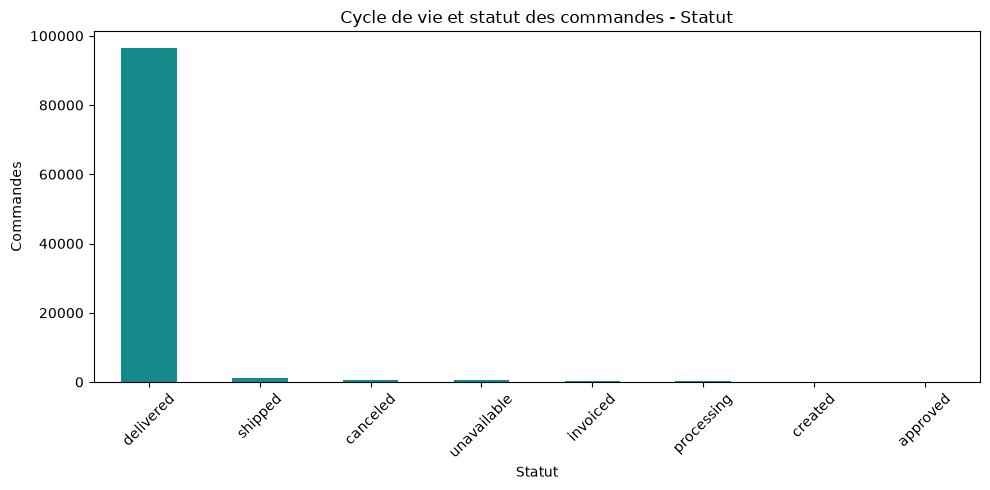

Visuel 2 - Cycle de vie et statut des commandes - Mois d’achat


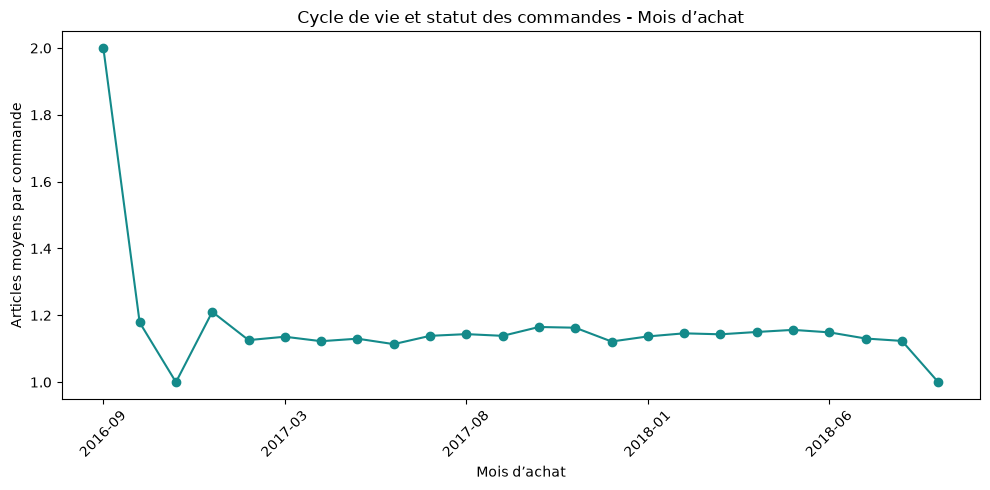

Visuel 3 - Cycle de vie et statut des commandes - Mois d’approbation


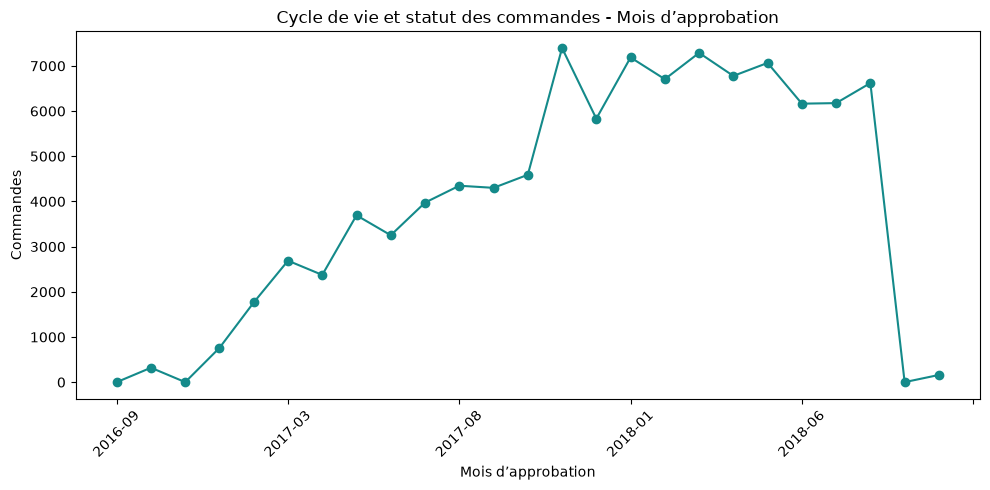

Visuel 4 - Cycle de vie et statut des commandes - Mois expédition


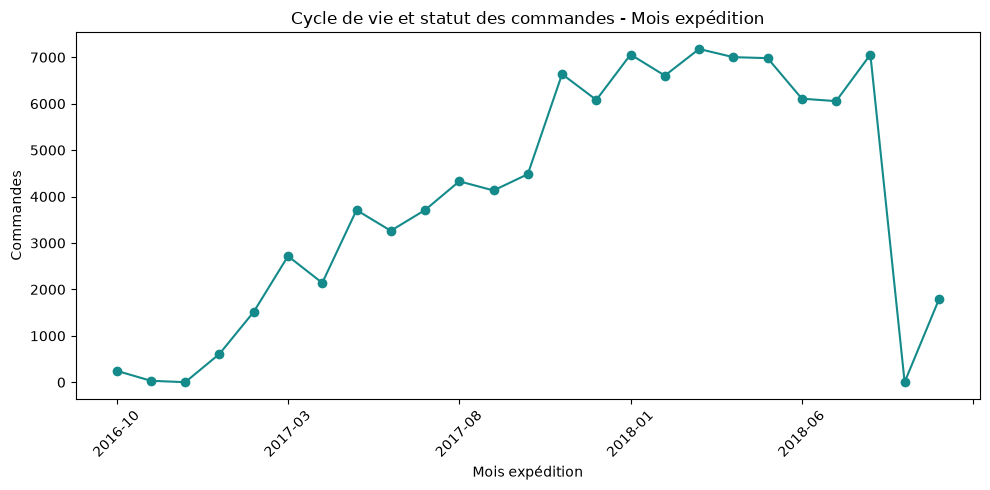

Visuel 5 - Cycle de vie et statut des commandes - Mois livraison


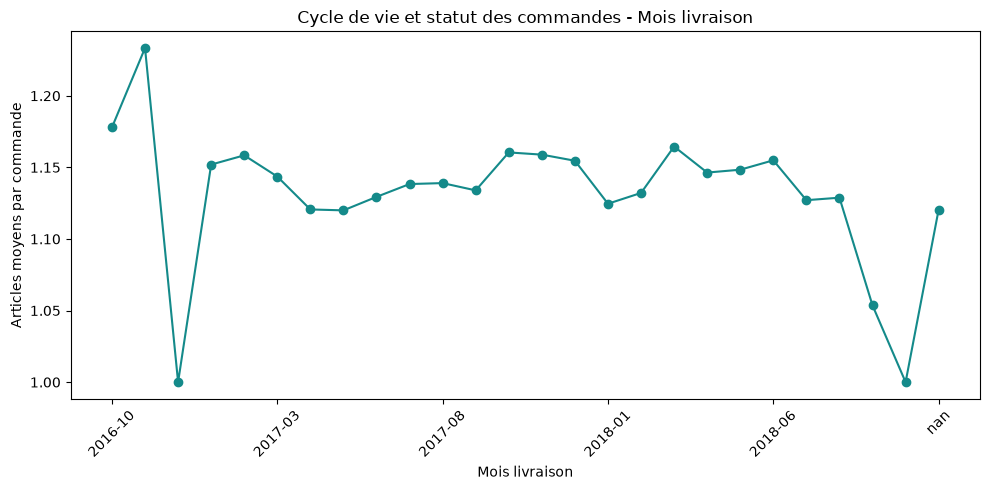

Visuel 6 - Cycle de vie et statut des commandes - Mois estimé


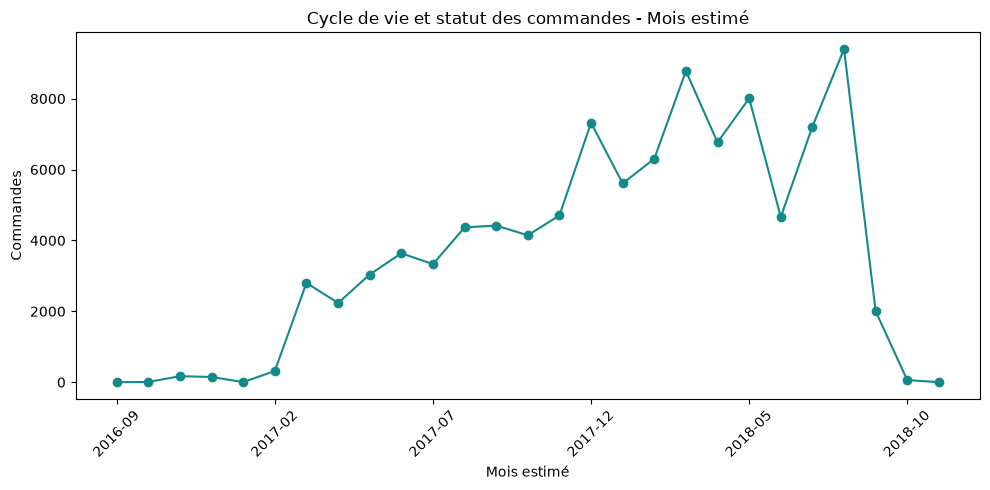

Visuel 7 - Cycle de vie et statut des commandes - État client


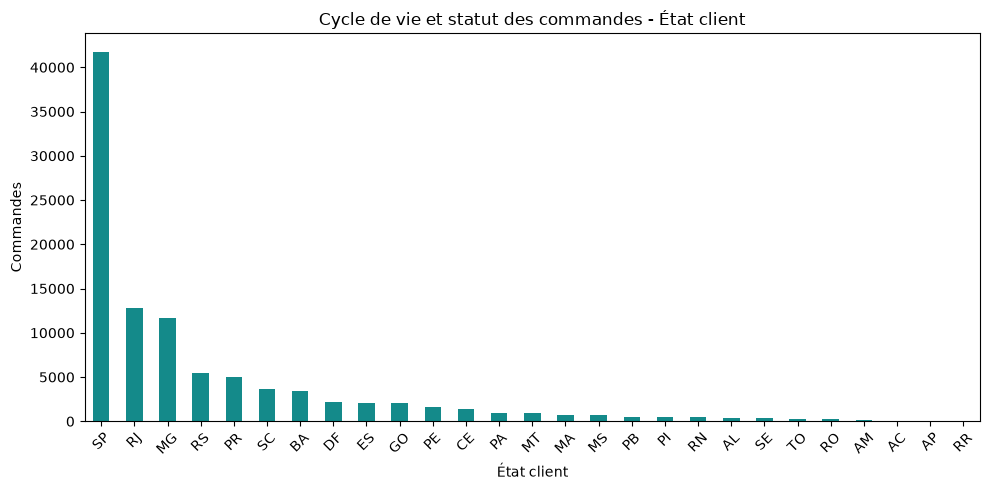

Visuel 8 - Cycle de vie et statut des commandes - Partie du jour achat


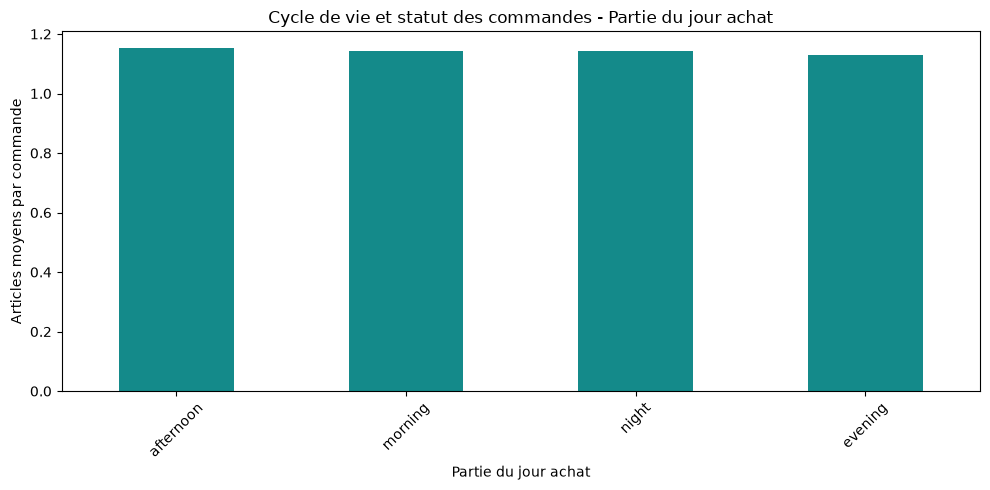

Visuel 9 - Cycle de vie et statut des commandes - Statut x mois achat


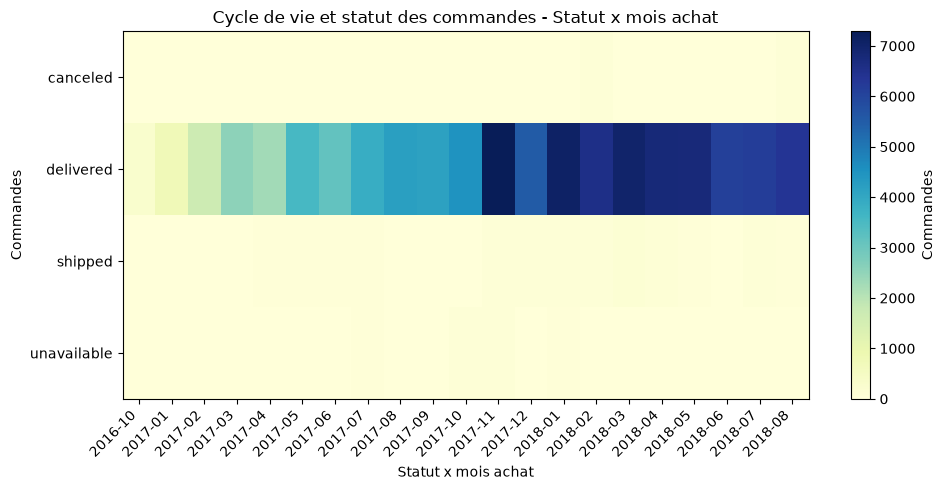

Visuel 10 - Cycle de vie et statut des commandes - Statut x état client


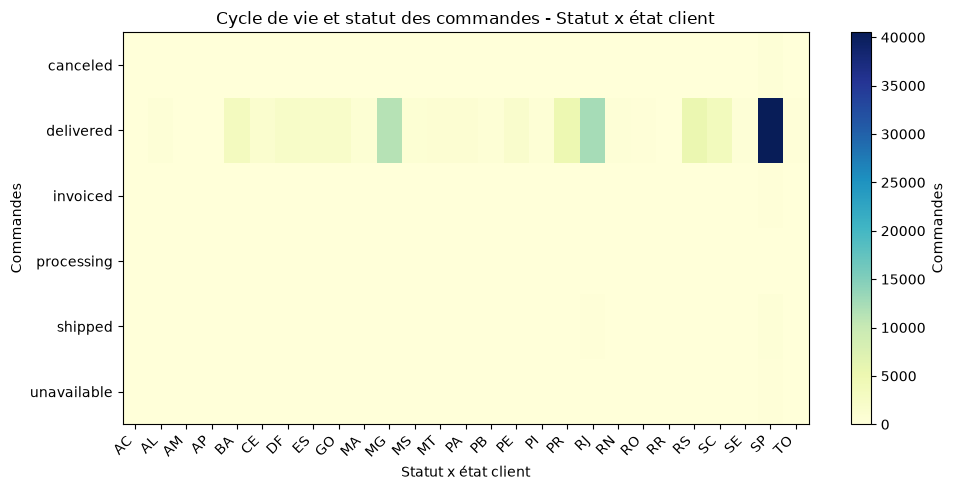

In [3]:
CHARTS=[
  {
    "n": 1,
    "title": "Cycle de vie et statut des commandes - Statut",
    "dim": {
      "label": "Statut",
      "sql": "\"status\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes",
      "sql": "COUNT(*)",
      "pandas": "orders"
    },
    "kind": "bar"
  },
  {
    "n": 2,
    "title": "Cycle de vie et statut des commandes - Mois d’achat",
    "dim": {
      "label": "Mois d’achat",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Articles moyens par commande",
      "sql": "AVG(\"item_count\")",
      "pandas": "item_count"
    },
    "kind": "line"
  },
  {
    "n": 3,
    "title": "Cycle de vie et statut des commandes - Mois d’approbation",
    "dim": {
      "label": "Mois d’approbation",
      "sql": "SUBSTRING(\"approved_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Commandes",
      "sql": "COUNT(*)",
      "pandas": "orders"
    },
    "kind": "line"
  },
  {
    "n": 4,
    "title": "Cycle de vie et statut des commandes - Mois expédition",
    "dim": {
      "label": "Mois expédition",
      "sql": "SUBSTRING(\"shipped_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Commandes",
      "sql": "COUNT(*)",
      "pandas": "orders"
    },
    "kind": "line"
  },
  {
    "n": 5,
    "title": "Cycle de vie et statut des commandes - Mois livraison",
    "dim": {
      "label": "Mois livraison",
      "sql": "SUBSTRING(\"delivered_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Articles moyens par commande",
      "sql": "AVG(\"item_count\")",
      "pandas": "item_count"
    },
    "kind": "line"
  },
  {
    "n": 6,
    "title": "Cycle de vie et statut des commandes - Mois estimé",
    "dim": {
      "label": "Mois estimé",
      "sql": "SUBSTRING(\"estimated_delivery_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Commandes",
      "sql": "COUNT(*)",
      "pandas": "orders"
    },
    "kind": "line"
  },
  {
    "n": 7,
    "title": "Cycle de vie et statut des commandes - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes",
      "sql": "COUNT(*)",
      "pandas": "orders"
    },
    "kind": "bar"
  },
  {
    "n": 8,
    "title": "Cycle de vie et statut des commandes - Partie du jour achat",
    "dim": {
      "label": "Partie du jour achat",
      "sql": "\"purchase_time_day_part\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Articles moyens par commande",
      "sql": "AVG(\"item_count\")",
      "pandas": "item_count"
    },
    "kind": "bar"
  },
  {
    "n": 9,
    "title": "Cycle de vie et statut des commandes - Statut x mois achat",
    "dim": {
      "label": "Statut x mois achat",
      "sql": "\"status\"",
      "type": "categorical",
      "series": "SUBSTRING(\"purchase_date_calendar_date\",1,7)"
    },
    "metric": {
      "label": "Commandes",
      "sql": "COUNT(*)",
      "pandas": "orders"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Cycle de vie et statut des commandes - Statut x état client",
    "dim": {
      "label": "Statut x état client",
      "sql": "\"status\"",
      "type": "categorical",
      "series": "\"customer_state\""
    },
    "metric": {
      "label": "Commandes",
      "sql": "COUNT(*)",
      "pandas": "orders"
    },
    "kind": "heatmap"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## 2. Valeur des paniers et composition

Comparer les commandes par montant produits, fret, paiement et composition d’articles tout en conservant le grain commande.

**Drill-down :** État client > ville; statut et période d’achat; commande > nombre d’articles/produits/vendeurs.

Visuel 1 - Valeur des paniers et composition - Mois d’achat


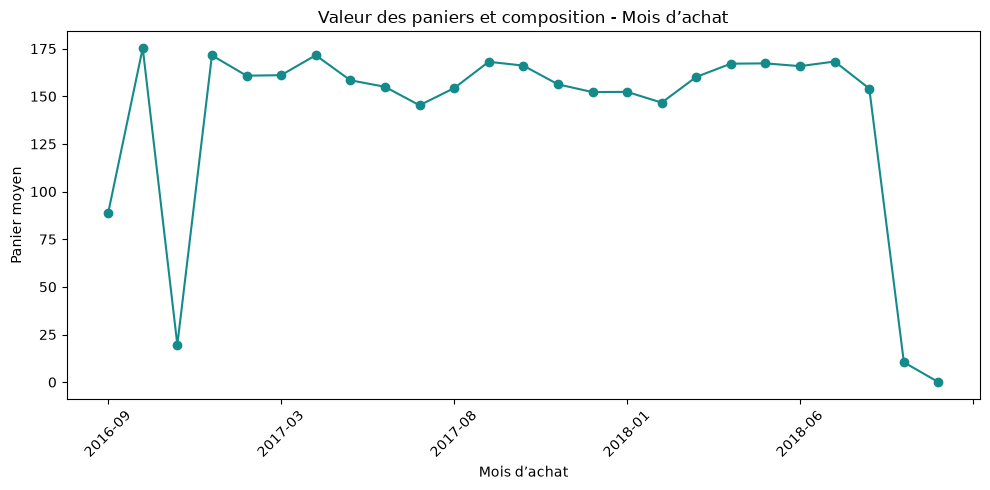

Visuel 2 - Valeur des paniers et composition - Statut


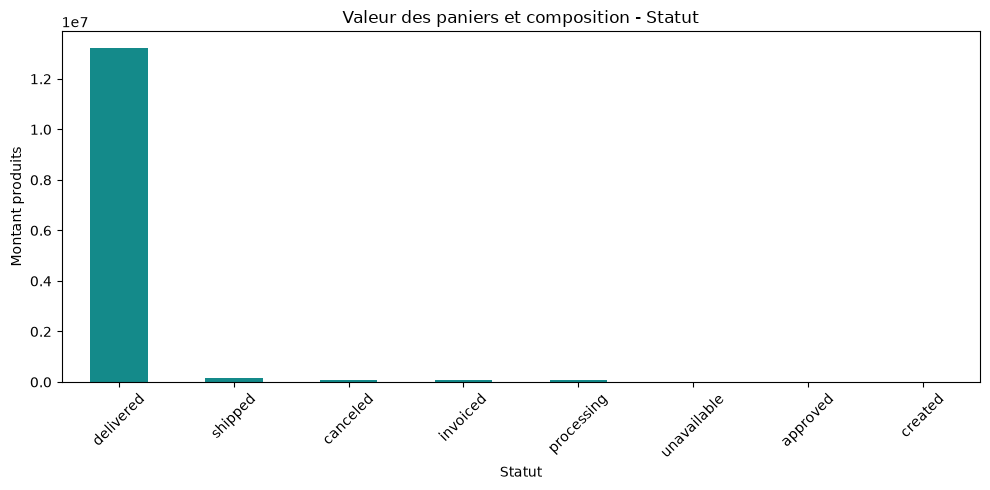

Visuel 3 - Valeur des paniers et composition - État client


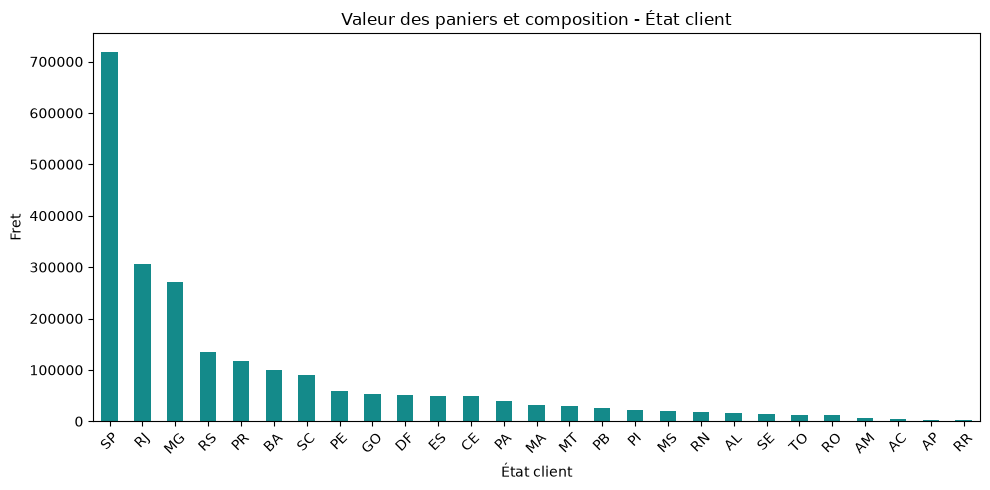

Visuel 4 - Valeur des paniers et composition - Ville client


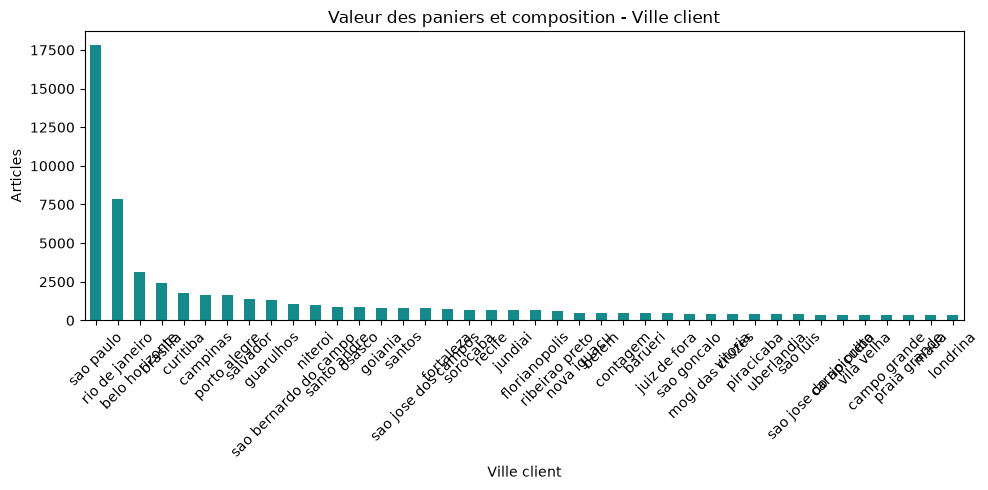

Visuel 5 - Valeur des paniers et composition - Articles par tranche


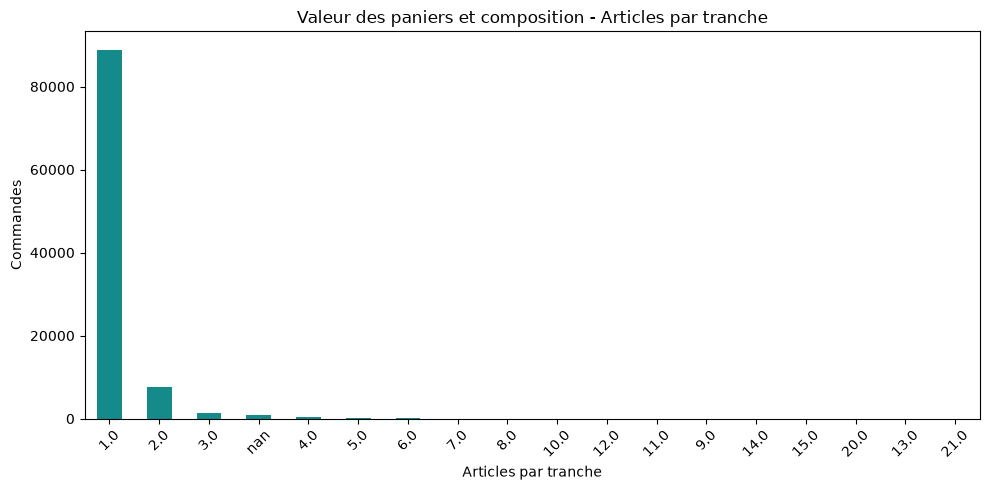

Visuel 6 - Valeur des paniers et composition - Produits par tranche


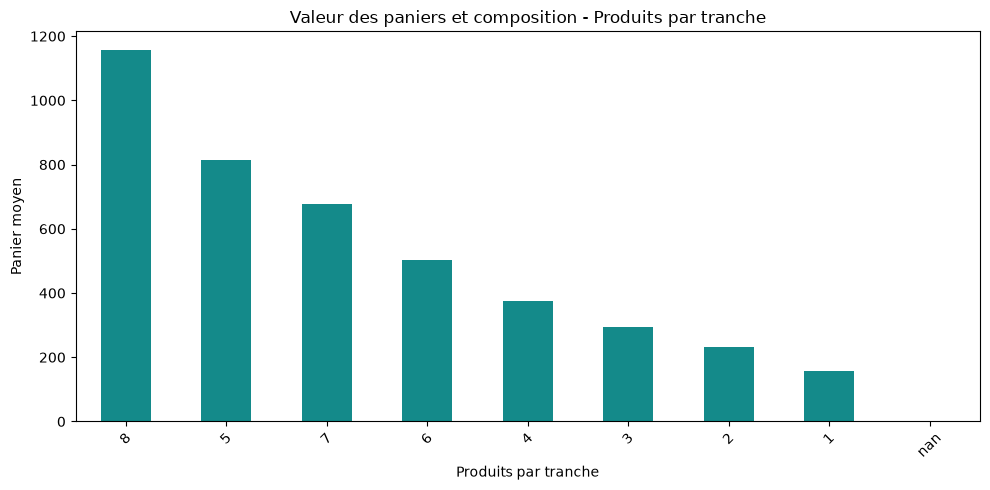

Visuel 7 - Valeur des paniers et composition - Vendeurs par tranche


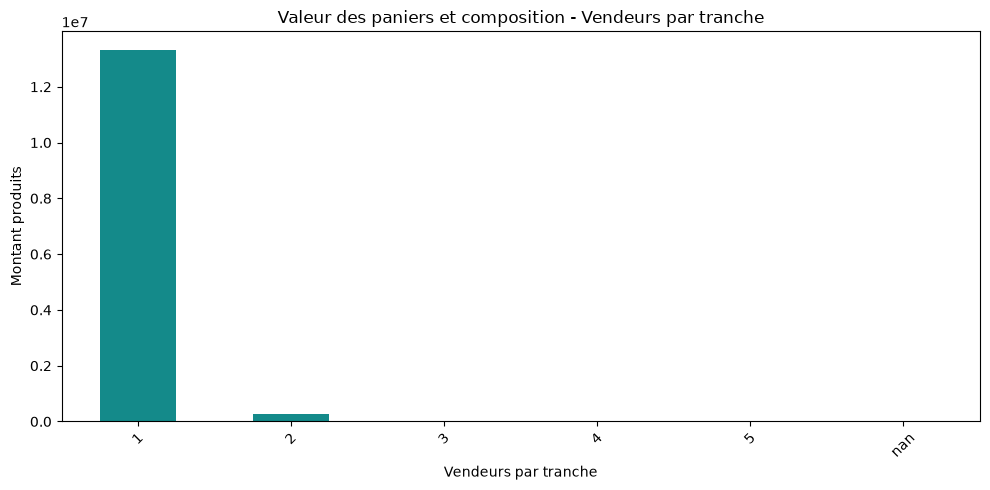

Visuel 8 - Valeur des paniers et composition - Statut x mois


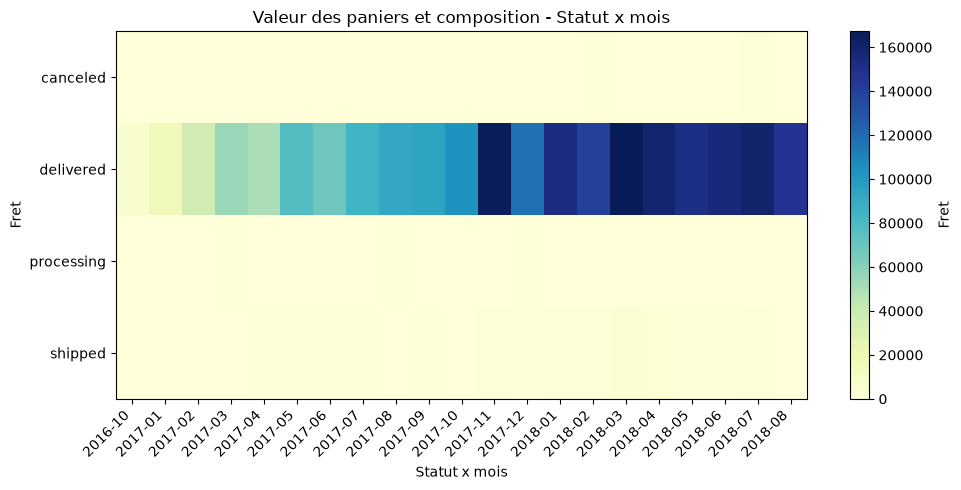

Visuel 9 - Valeur des paniers et composition - État x statut


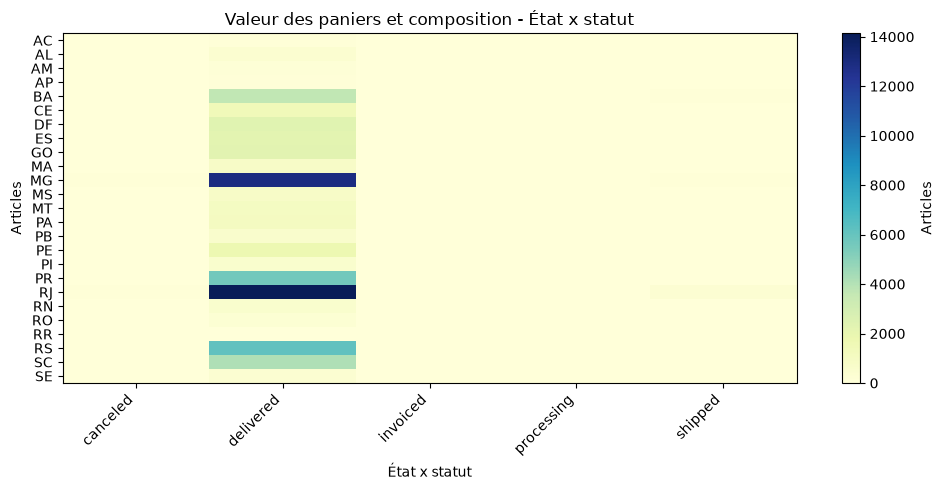

Visuel 10 - Valeur des paniers et composition - Partie du jour


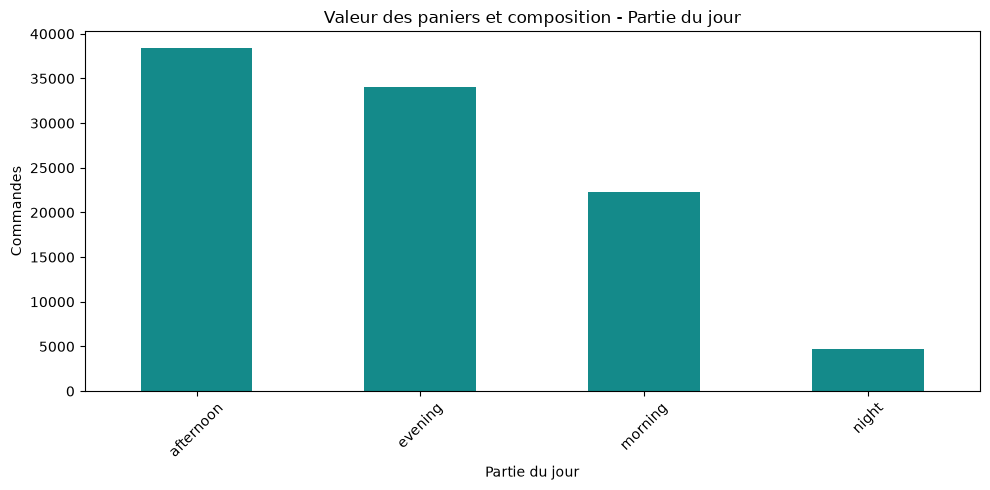

In [4]:
CHARTS=[
  {
    "n": 1,
    "title": "Valeur des paniers et composition - Mois d’achat",
    "dim": {
      "label": "Mois d’achat",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Panier moyen",
      "sql": "SUM(\"product_amount\" + \"freight_amount\") / NULLIF(COUNT(*),0)",
      "pandas": "average_order_value"
    },
    "kind": "line"
  },
  {
    "n": 2,
    "title": "Valeur des paniers et composition - Statut",
    "dim": {
      "label": "Statut",
      "sql": "\"status\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Montant produits",
      "sql": "SUM(\"product_amount\")",
      "pandas": "product_amount"
    },
    "kind": "bar"
  },
  {
    "n": 3,
    "title": "Valeur des paniers et composition - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Fret",
      "sql": "SUM(\"freight_amount\")",
      "pandas": "freight_amount"
    },
    "kind": "bar"
  },
  {
    "n": 4,
    "title": "Valeur des paniers et composition - Ville client",
    "dim": {
      "label": "Ville client",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Articles",
      "sql": "SUM(\"item_count\")",
      "pandas": "item_count"
    },
    "kind": "bar"
  },
  {
    "n": 5,
    "title": "Valeur des paniers et composition - Articles par tranche",
    "dim": {
      "label": "Articles par tranche",
      "sql": "\"item_count\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Commandes",
      "sql": "COUNT(*)",
      "pandas": "orders"
    },
    "kind": "bar"
  },
  {
    "n": 6,
    "title": "Valeur des paniers et composition - Produits par tranche",
    "dim": {
      "label": "Produits par tranche",
      "sql": "\"product_count\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Panier moyen",
      "sql": "SUM(\"product_amount\" + \"freight_amount\") / NULLIF(COUNT(*),0)",
      "pandas": "average_order_value"
    },
    "kind": "bar"
  },
  {
    "n": 7,
    "title": "Valeur des paniers et composition - Vendeurs par tranche",
    "dim": {
      "label": "Vendeurs par tranche",
      "sql": "\"seller_count\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Montant produits",
      "sql": "SUM(\"product_amount\")",
      "pandas": "product_amount"
    },
    "kind": "bar"
  },
  {
    "n": 8,
    "title": "Valeur des paniers et composition - Statut x mois",
    "dim": {
      "label": "Statut x mois",
      "sql": "\"status\"",
      "type": "categorical",
      "series": "SUBSTRING(\"purchase_date_calendar_date\",1,7)"
    },
    "metric": {
      "label": "Fret",
      "sql": "SUM(\"freight_amount\")",
      "pandas": "freight_amount"
    },
    "kind": "heatmap"
  },
  {
    "n": 9,
    "title": "Valeur des paniers et composition - État x statut",
    "dim": {
      "label": "État x statut",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": "\"status\""
    },
    "metric": {
      "label": "Articles",
      "sql": "SUM(\"item_count\")",
      "pandas": "item_count"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Valeur des paniers et composition - Partie du jour",
    "dim": {
      "label": "Partie du jour",
      "sql": "\"purchase_time_day_part\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes",
      "sql": "COUNT(*)",
      "pandas": "orders"
    },
    "kind": "bar"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## 3. Réconciliation entre paiements et panier

Analyser l’écart calculé entre paiement et total produits + fret, sa distribution et les segments dans lesquels il apparaît.

**Drill-down :** Écart total > statut > période > état client > commande via order_id.

Visuel 1 - Réconciliation entre paiements et panier - Statut


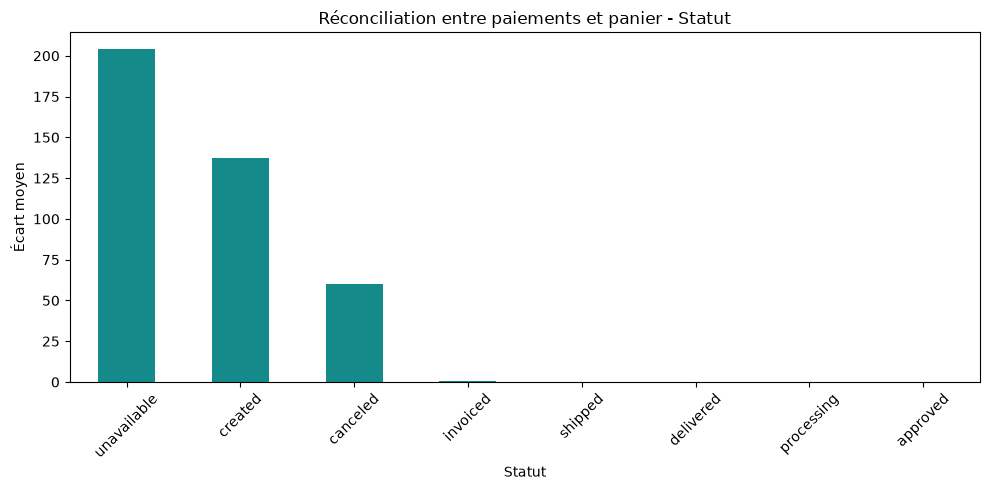

Visuel 2 - Réconciliation entre paiements et panier - Mois achat


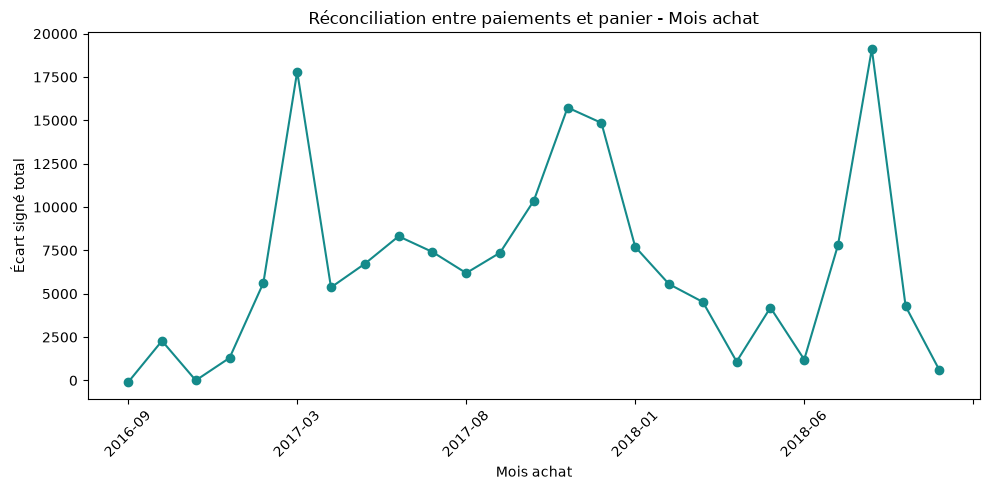

Visuel 3 - Réconciliation entre paiements et panier - État client


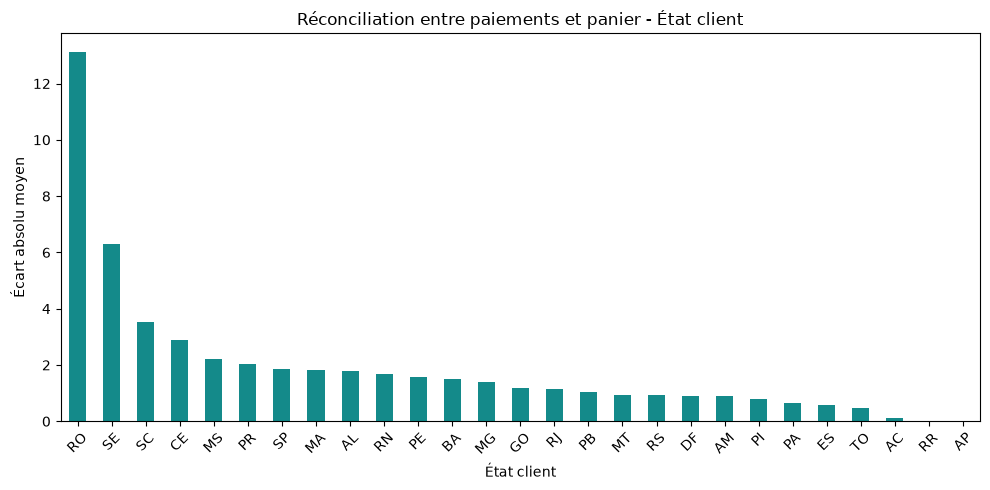

Visuel 4 - Réconciliation entre paiements et panier - Tranche écart (5)


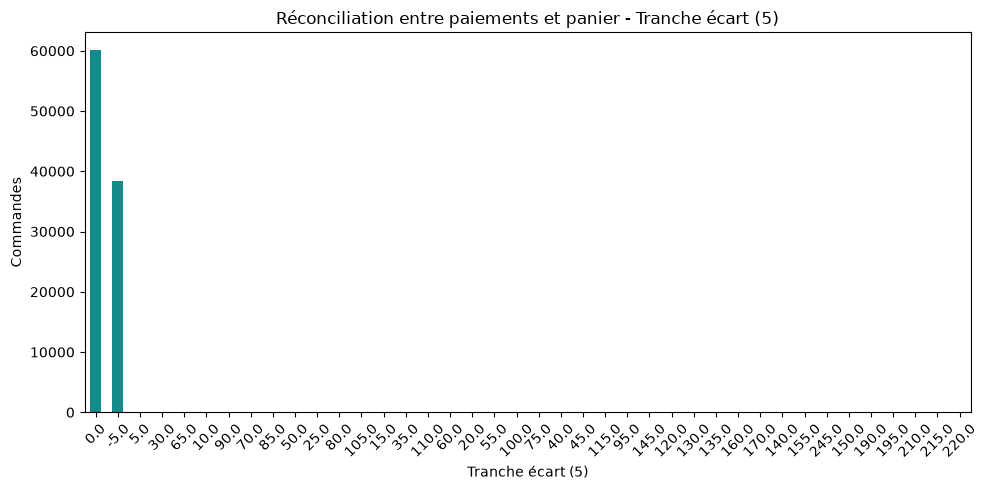

Visuel 5 - Réconciliation entre paiements et panier - Tranche paiement (50)


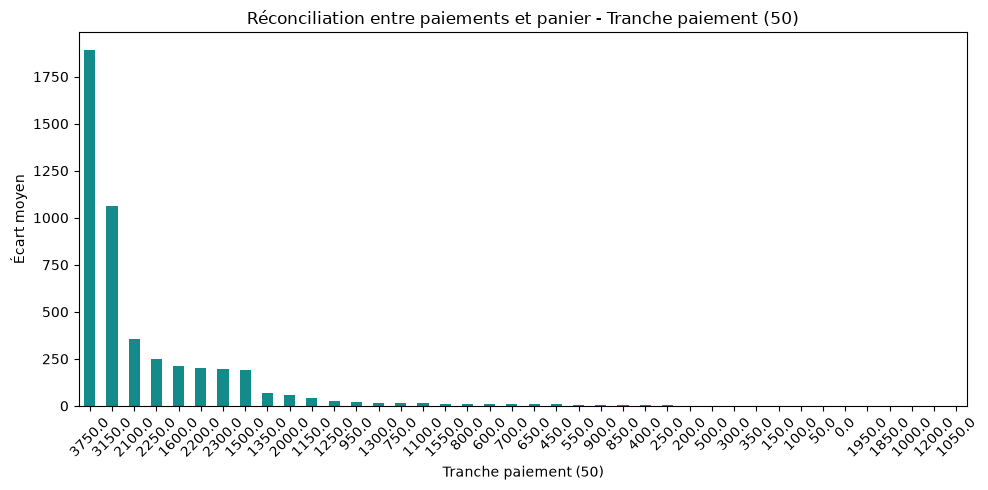

Visuel 6 - Réconciliation entre paiements et panier - Articles par tranche


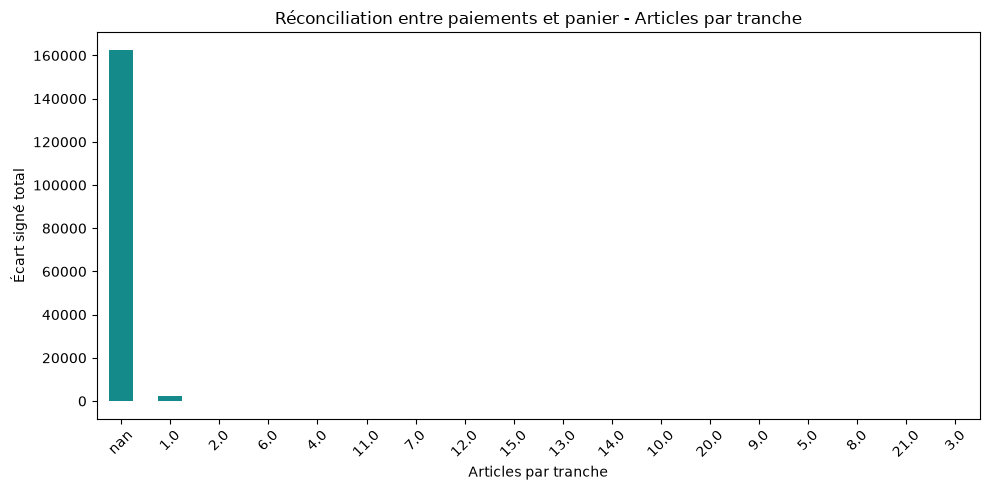

Visuel 7 - Réconciliation entre paiements et panier - Commandes au plus grand écart


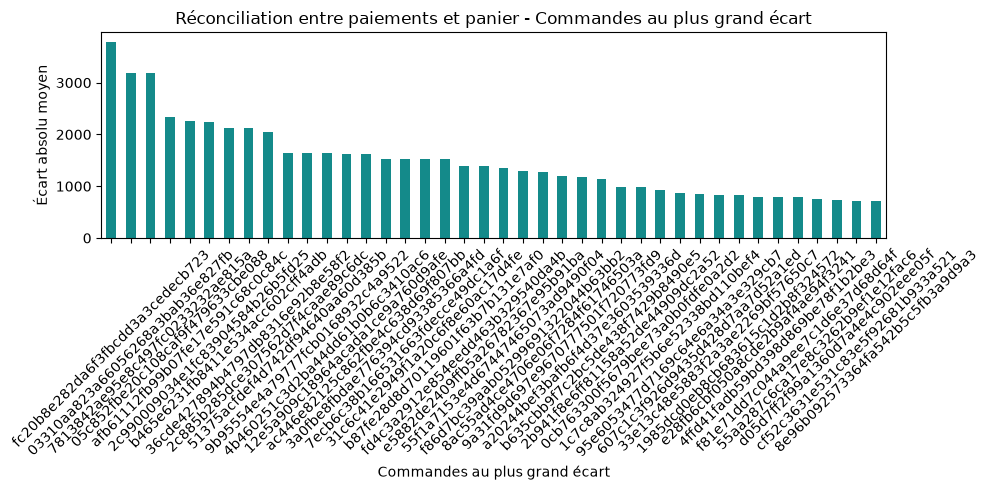

Visuel 8 - Réconciliation entre paiements et panier - Statut x mois


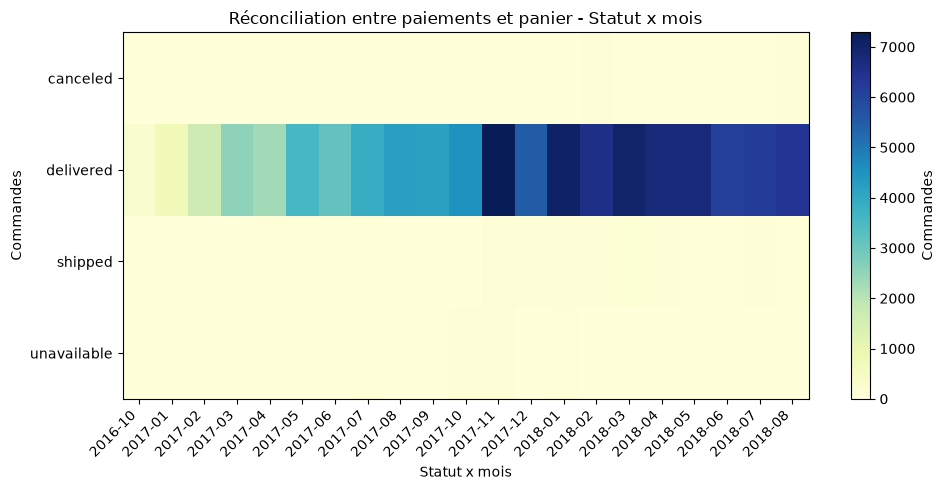

Visuel 9 - Réconciliation entre paiements et panier - État x statut


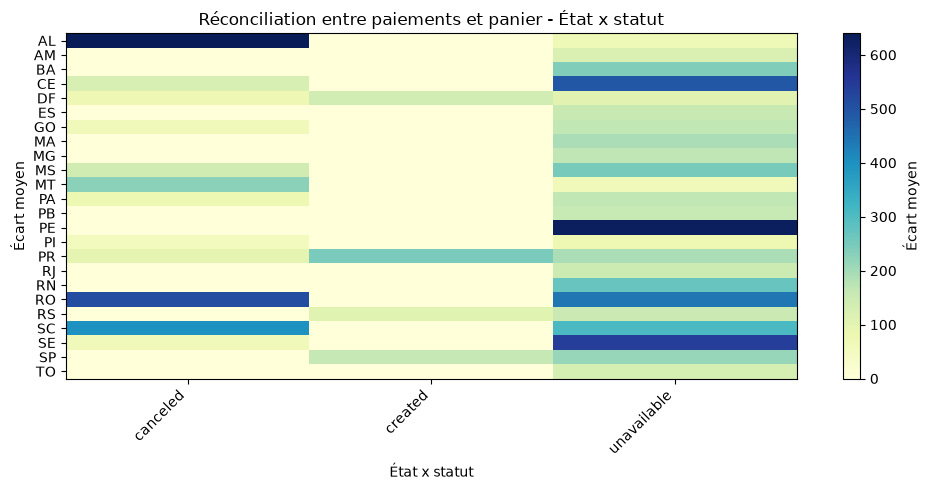

Visuel 10 - Réconciliation entre paiements et panier - Partie du jour


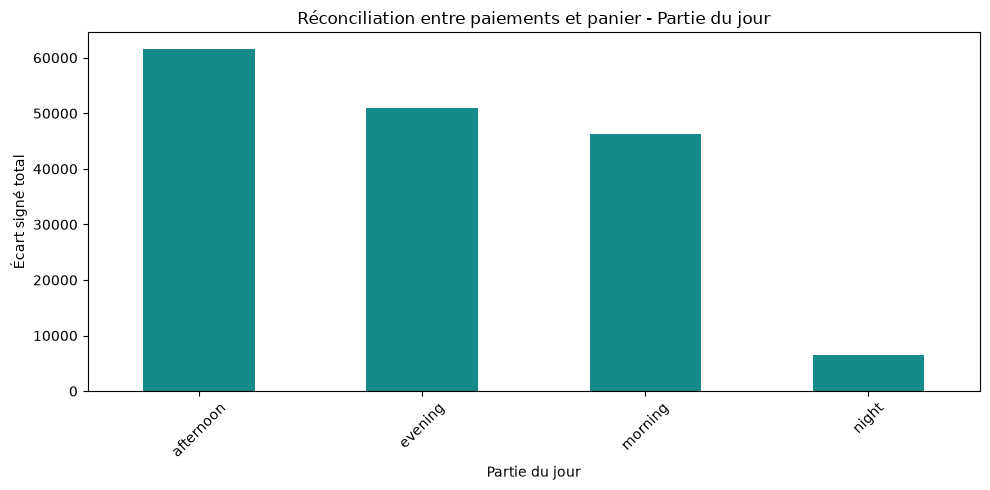

In [5]:
CHARTS=[
  {
    "n": 1,
    "title": "Réconciliation entre paiements et panier - Statut",
    "dim": {
      "label": "Statut",
      "sql": "\"status\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Écart moyen",
      "sql": "AVG(\"payment_gap\")",
      "pandas": "payment_gap"
    },
    "kind": "bar"
  },
  {
    "n": 2,
    "title": "Réconciliation entre paiements et panier - Mois achat",
    "dim": {
      "label": "Mois achat",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Écart signé total",
      "sql": "SUM(\"payment_gap\")",
      "pandas": "payment_gap"
    },
    "kind": "line"
  },
  {
    "n": 3,
    "title": "Réconciliation entre paiements et panier - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Écart absolu moyen",
      "sql": "AVG(ABS(\"payment_gap\"))",
      "pandas": "payment_gap"
    },
    "kind": "bar"
  },
  {
    "n": 4,
    "title": "Réconciliation entre paiements et panier - Tranche écart (5)",
    "dim": {
      "label": "Tranche écart (5)",
      "sql": "FLOOR(\"payment_gap\"/5)*5",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Commandes",
      "sql": "COUNT(*)",
      "pandas": "orders"
    },
    "kind": "bar"
  },
  {
    "n": 5,
    "title": "Réconciliation entre paiements et panier - Tranche paiement (50)",
    "dim": {
      "label": "Tranche paiement (50)",
      "sql": "FLOOR(\"payment_amount\"/50)*50",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Écart moyen",
      "sql": "AVG(\"payment_gap\")",
      "pandas": "payment_gap"
    },
    "kind": "bar"
  },
  {
    "n": 6,
    "title": "Réconciliation entre paiements et panier - Articles par tranche",
    "dim": {
      "label": "Articles par tranche",
      "sql": "\"item_count\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Écart signé total",
      "sql": "SUM(\"payment_gap\")",
      "pandas": "payment_gap"
    },
    "kind": "bar"
  },
  {
    "n": 7,
    "title": "Réconciliation entre paiements et panier - Commandes au plus grand écart",
    "dim": {
      "label": "Commandes au plus grand écart",
      "sql": "\"order_id\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Écart absolu moyen",
      "sql": "AVG(ABS(\"payment_gap\"))",
      "pandas": "payment_gap"
    },
    "kind": "bar"
  },
  {
    "n": 8,
    "title": "Réconciliation entre paiements et panier - Statut x mois",
    "dim": {
      "label": "Statut x mois",
      "sql": "\"status\"",
      "type": "categorical",
      "series": "SUBSTRING(\"purchase_date_calendar_date\",1,7)"
    },
    "metric": {
      "label": "Commandes",
      "sql": "COUNT(*)",
      "pandas": "orders"
    },
    "kind": "heatmap"
  },
  {
    "n": 9,
    "title": "Réconciliation entre paiements et panier - État x statut",
    "dim": {
      "label": "État x statut",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": "\"status\""
    },
    "metric": {
      "label": "Écart moyen",
      "sql": "AVG(\"payment_gap\")",
      "pandas": "payment_gap"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Réconciliation entre paiements et panier - Partie du jour",
    "dim": {
      "label": "Partie du jour",
      "sql": "\"purchase_time_day_part\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Écart signé total",
      "sql": "SUM(\"payment_gap\")",
      "pandas": "payment_gap"
    },
    "kind": "bar"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## 4. Structure et complexité de la commande

Évaluer la composition des commandes par nombre d’articles, de produits distincts et de vendeurs associés.

**Drill-down :** Commande > statut; articles / produits / vendeurs; état > ville; période et partie du jour.

Visuel 1 - Structure et complexité de la commande - Articles


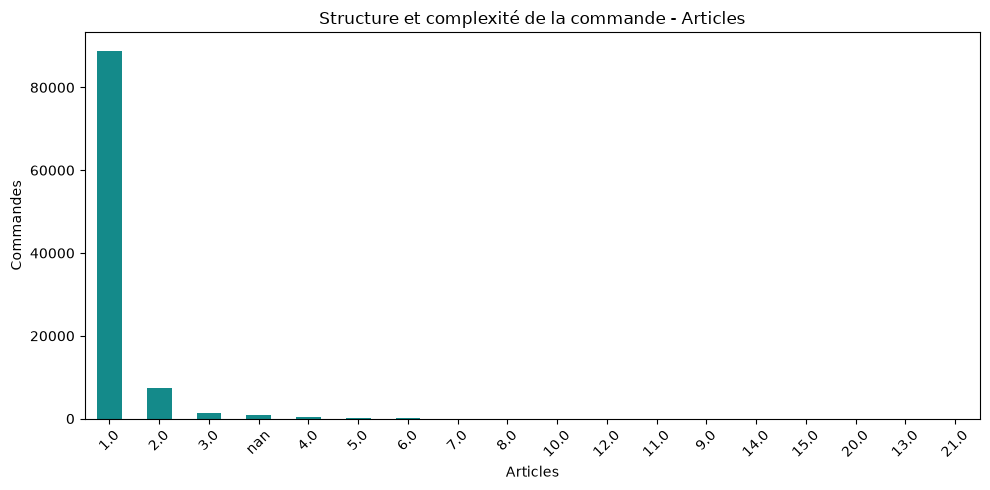

Visuel 2 - Structure et complexité de la commande - Produits distincts


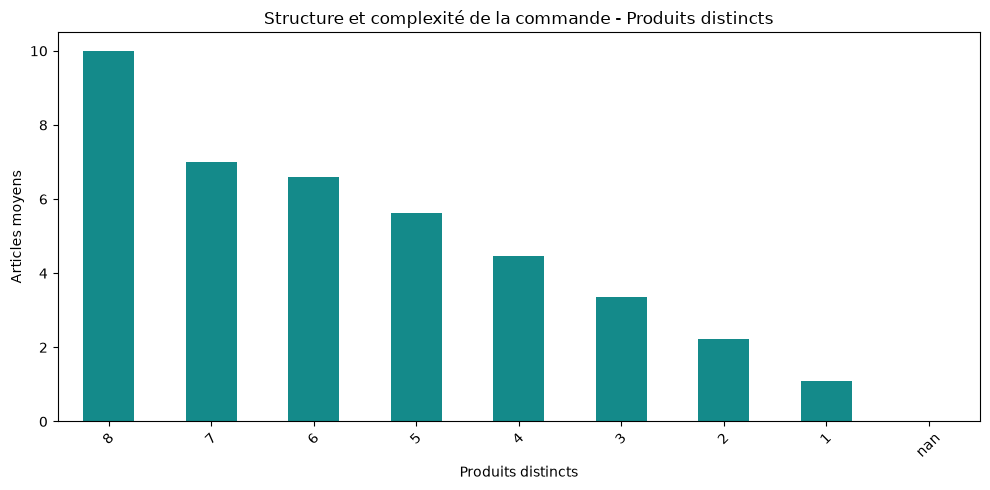

Visuel 3 - Structure et complexité de la commande - Vendeurs


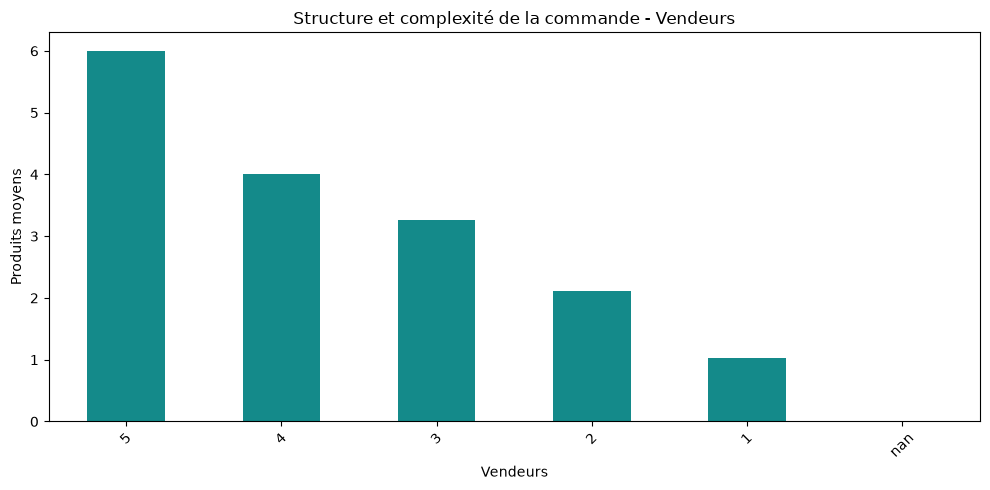

Visuel 4 - Structure et complexité de la commande - Statut


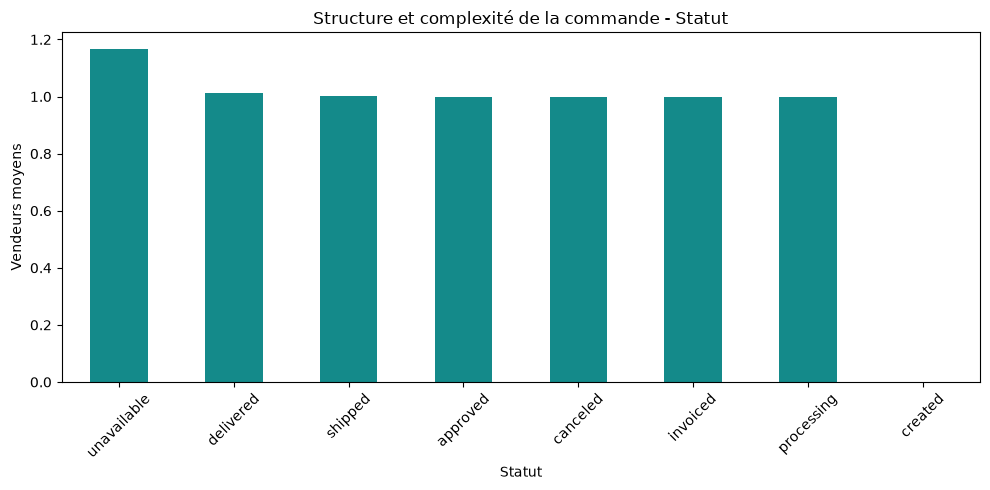

Visuel 5 - Structure et complexité de la commande - État client


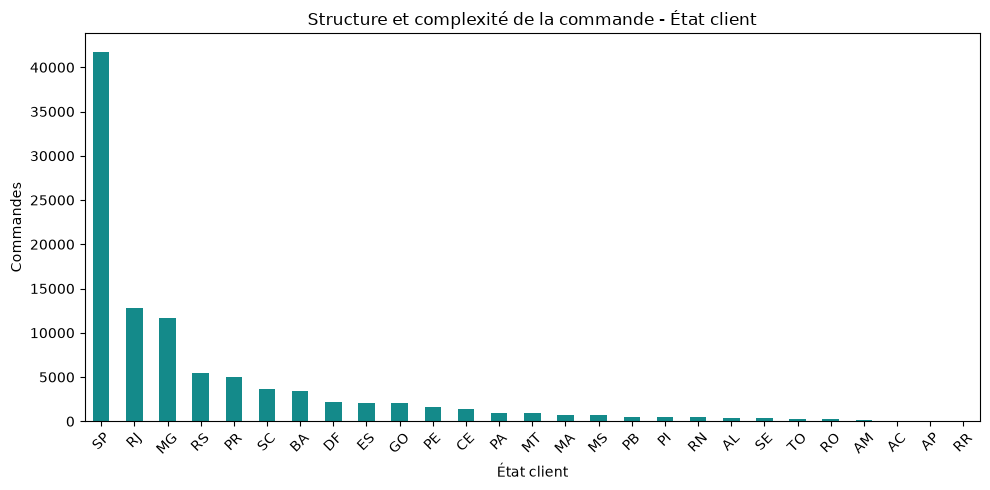

Visuel 6 - Structure et complexité de la commande - Ville client


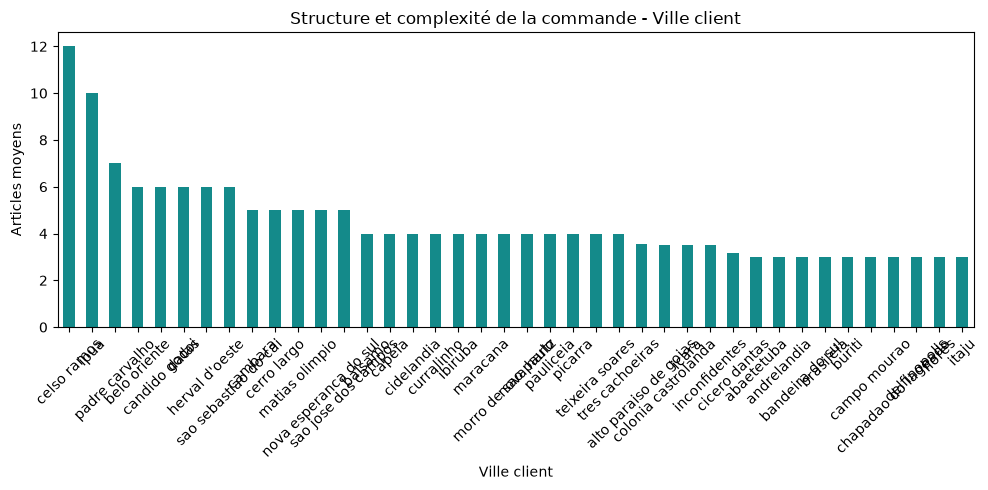

Visuel 7 - Structure et complexité de la commande - Mois achat


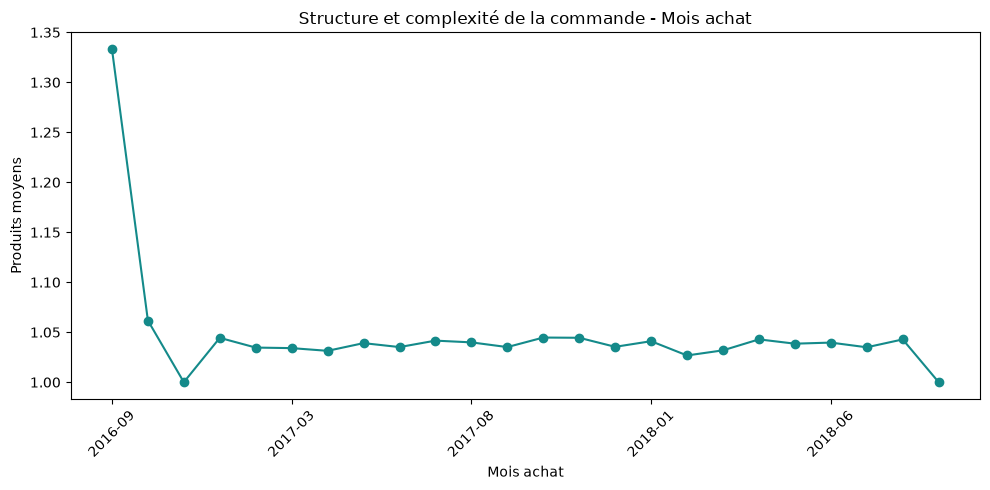

Visuel 8 - Structure et complexité de la commande - Articles x vendeurs


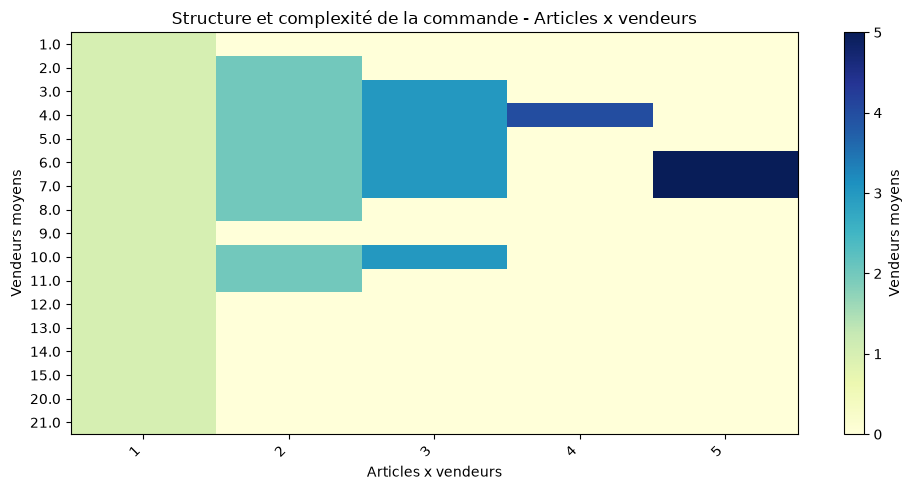

Visuel 9 - Structure et complexité de la commande - Statut x articles


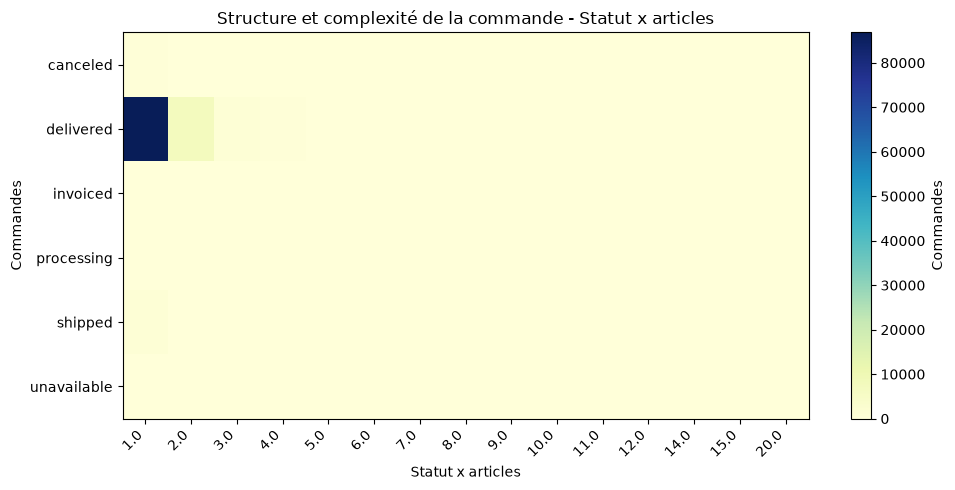

Visuel 10 - Structure et complexité de la commande - Partie du jour


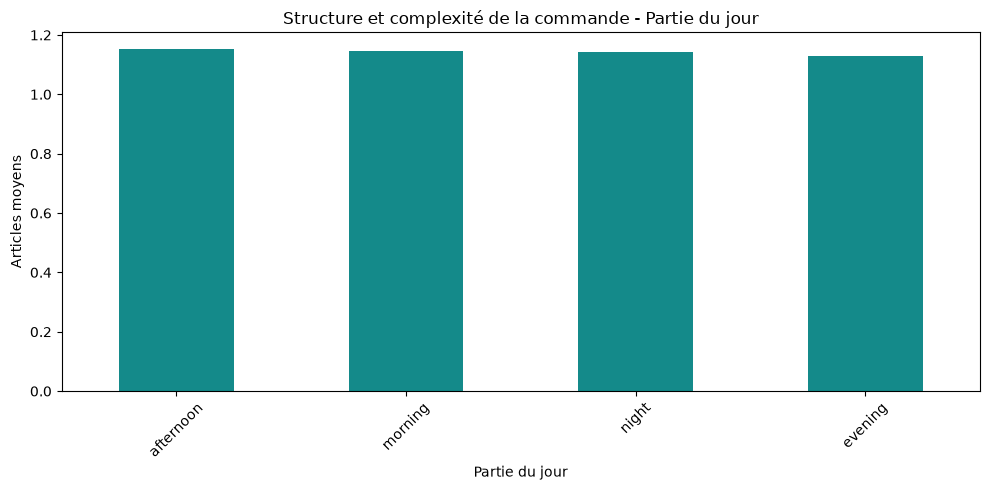

In [6]:
CHARTS=[
  {
    "n": 1,
    "title": "Structure et complexité de la commande - Articles",
    "dim": {
      "label": "Articles",
      "sql": "\"item_count\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Commandes",
      "sql": "COUNT(*)",
      "pandas": "orders"
    },
    "kind": "bar"
  },
  {
    "n": 2,
    "title": "Structure et complexité de la commande - Produits distincts",
    "dim": {
      "label": "Produits distincts",
      "sql": "\"product_count\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Articles moyens",
      "sql": "AVG(\"item_count\")",
      "pandas": "item_count"
    },
    "kind": "bar"
  },
  {
    "n": 3,
    "title": "Structure et complexité de la commande - Vendeurs",
    "dim": {
      "label": "Vendeurs",
      "sql": "\"seller_count\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Produits moyens",
      "sql": "AVG(\"product_count\")",
      "pandas": "product_count"
    },
    "kind": "bar"
  },
  {
    "n": 4,
    "title": "Structure et complexité de la commande - Statut",
    "dim": {
      "label": "Statut",
      "sql": "\"status\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Vendeurs moyens",
      "sql": "AVG(\"seller_count\")",
      "pandas": "seller_count"
    },
    "kind": "bar"
  },
  {
    "n": 5,
    "title": "Structure et complexité de la commande - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes",
      "sql": "COUNT(*)",
      "pandas": "orders"
    },
    "kind": "bar"
  },
  {
    "n": 6,
    "title": "Structure et complexité de la commande - Ville client",
    "dim": {
      "label": "Ville client",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Articles moyens",
      "sql": "AVG(\"item_count\")",
      "pandas": "item_count"
    },
    "kind": "bar"
  },
  {
    "n": 7,
    "title": "Structure et complexité de la commande - Mois achat",
    "dim": {
      "label": "Mois achat",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Produits moyens",
      "sql": "AVG(\"product_count\")",
      "pandas": "product_count"
    },
    "kind": "line"
  },
  {
    "n": 8,
    "title": "Structure et complexité de la commande - Articles x vendeurs",
    "dim": {
      "label": "Articles x vendeurs",
      "sql": "\"item_count\"",
      "type": "numeric",
      "series": "\"seller_count\""
    },
    "metric": {
      "label": "Vendeurs moyens",
      "sql": "AVG(\"seller_count\")",
      "pandas": "seller_count"
    },
    "kind": "heatmap"
  },
  {
    "n": 9,
    "title": "Structure et complexité de la commande - Statut x articles",
    "dim": {
      "label": "Statut x articles",
      "sql": "\"status\"",
      "type": "categorical",
      "series": "\"item_count\""
    },
    "metric": {
      "label": "Commandes",
      "sql": "COUNT(*)",
      "pandas": "orders"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Structure et complexité de la commande - Partie du jour",
    "dim": {
      "label": "Partie du jour",
      "sql": "\"purchase_time_day_part\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Articles moyens",
      "sql": "AVG(\"item_count\")",
      "pandas": "item_count"
    },
    "kind": "bar"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## 5. Demande géographique et calendrier d’achat

Comparer les volumes et paniers par marché client et par calendrier d’achat pour orienter la planification.

**Drill-down :** État > ville > code postal; année > trimestre > mois > jour; partie du jour > heure.

Visuel 1 - Demande géographique et calendrier d’achat - État client


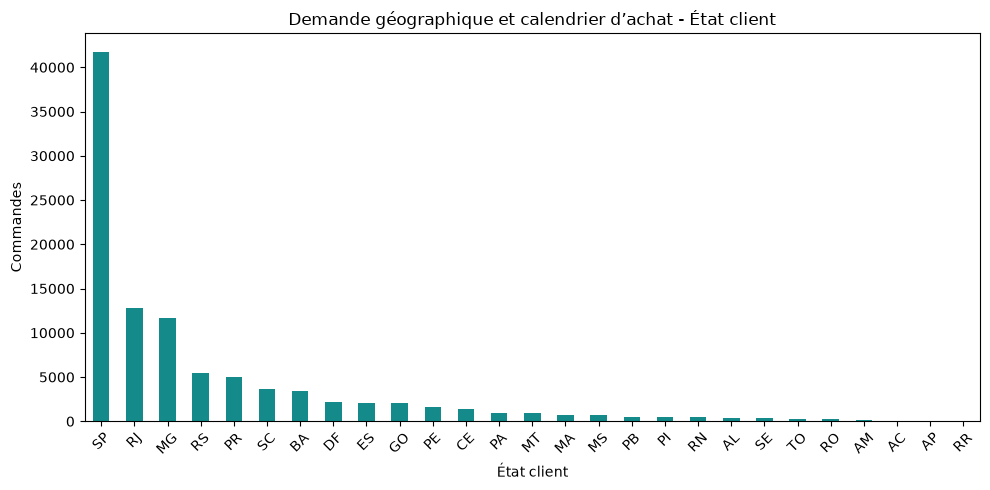

Visuel 2 - Demande géographique et calendrier d’achat - Ville client


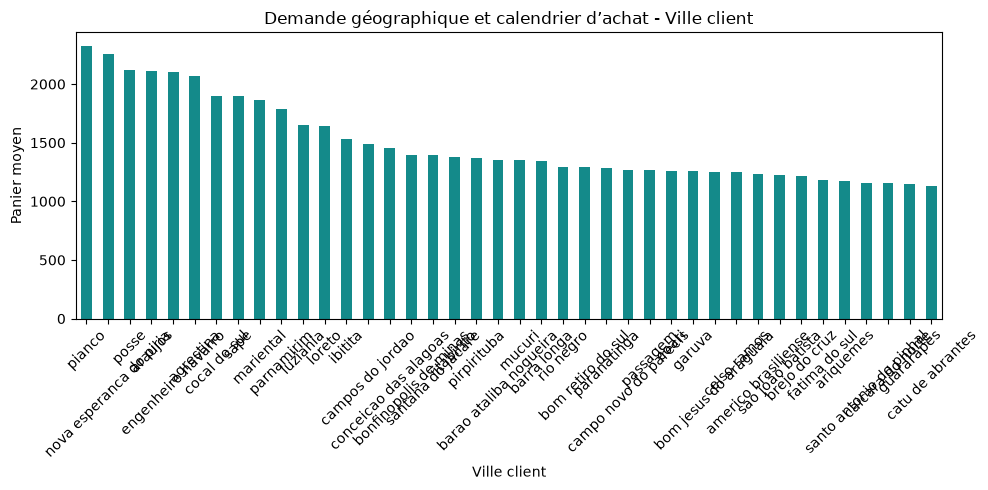

Visuel 3 - Demande géographique et calendrier d’achat - Code postal


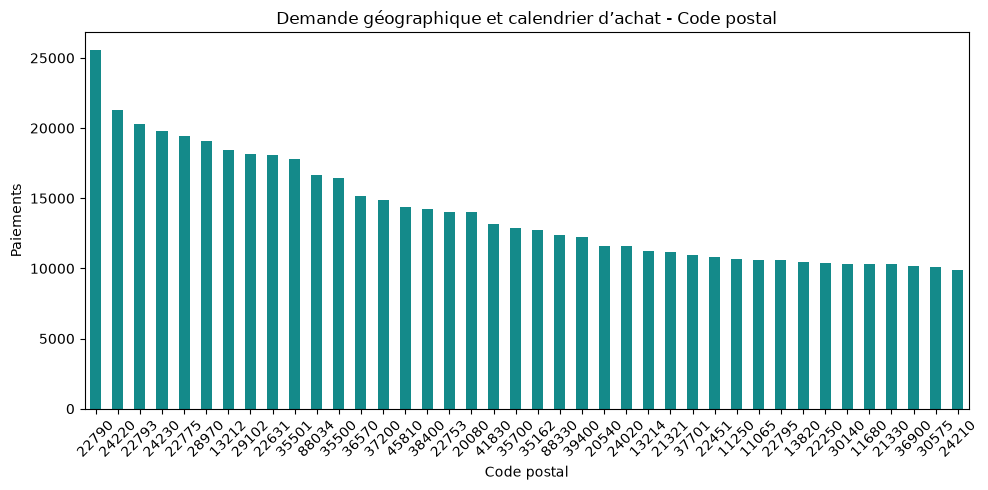

Visuel 4 - Demande géographique et calendrier d’achat - Mois achat


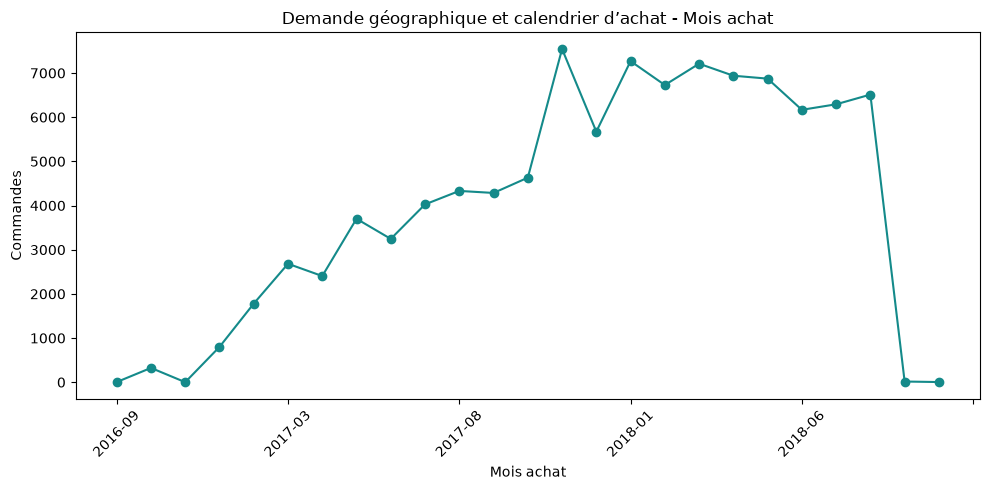

Visuel 5 - Demande géographique et calendrier d’achat - Année achat


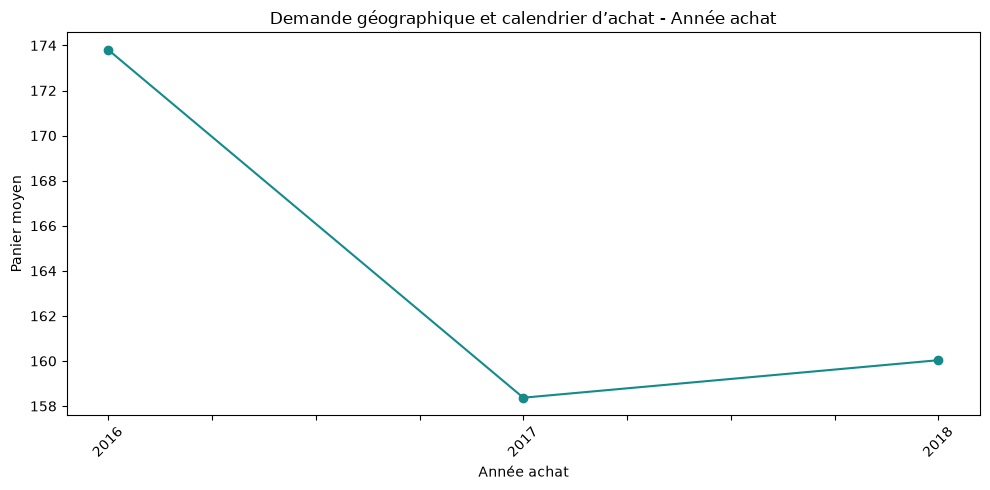

Visuel 6 - Demande géographique et calendrier d’achat - Trimestre achat


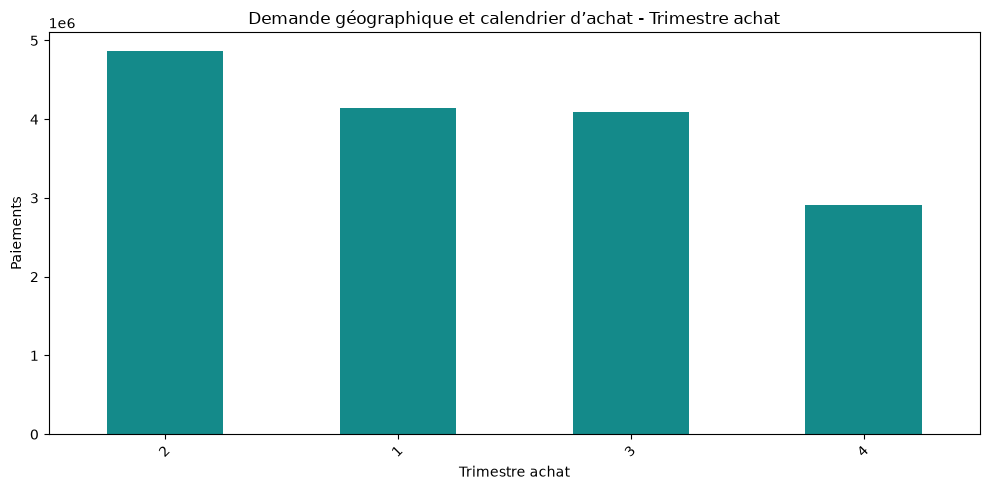

Visuel 7 - Demande géographique et calendrier d’achat - Jour semaine


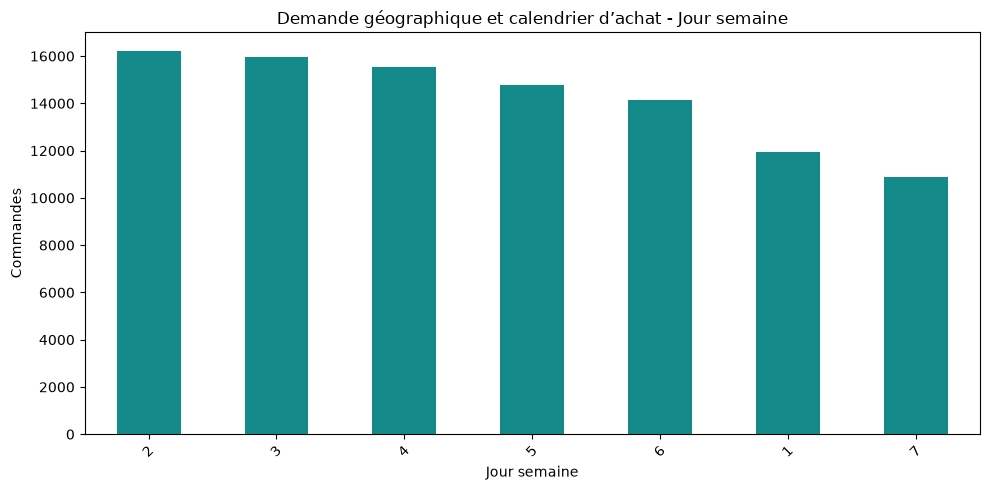

Visuel 8 - Demande géographique et calendrier d’achat - Heure achat


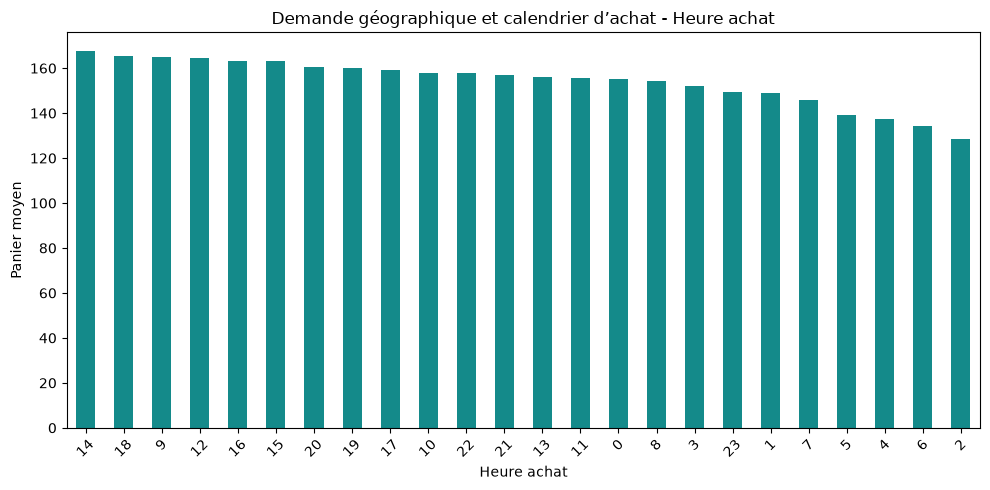

Visuel 9 - Demande géographique et calendrier d’achat - État x mois


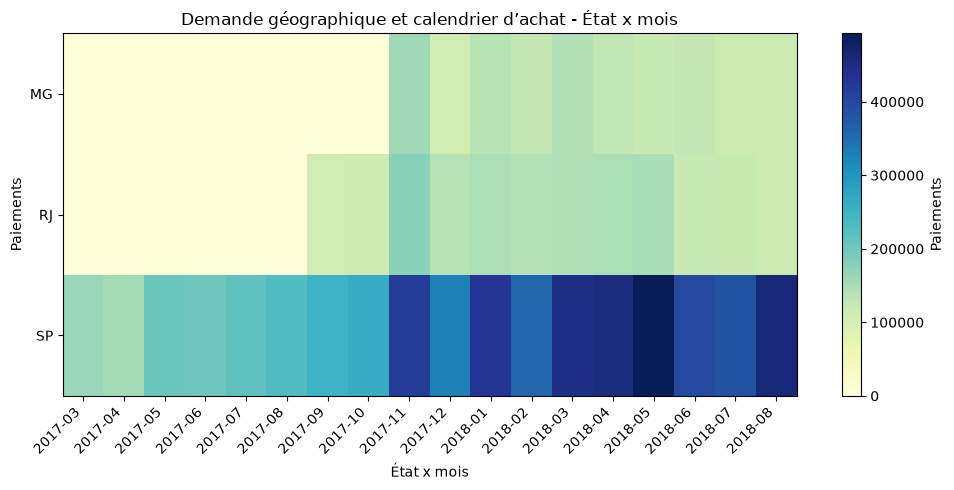

Visuel 10 - Demande géographique et calendrier d’achat - Ville x statut


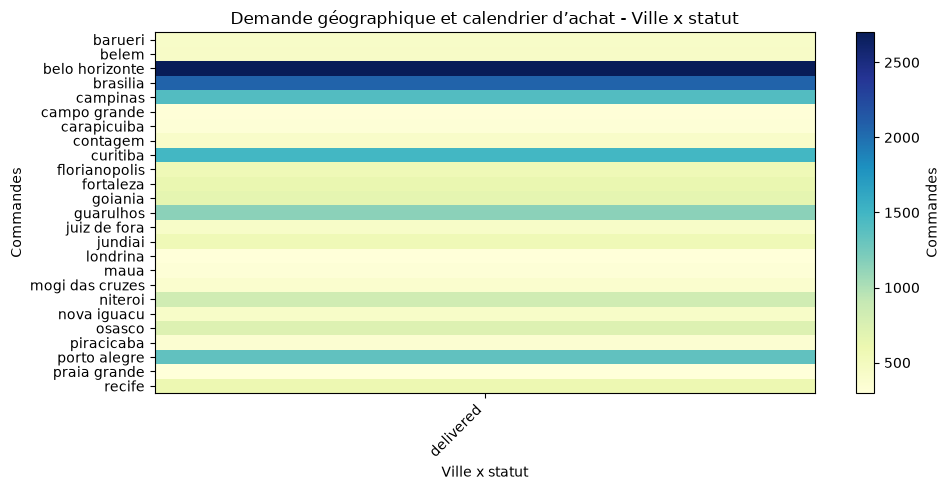

In [7]:
CHARTS=[
  {
    "n": 1,
    "title": "Demande géographique et calendrier d’achat - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes",
      "sql": "COUNT(*)",
      "pandas": "orders"
    },
    "kind": "bar"
  },
  {
    "n": 2,
    "title": "Demande géographique et calendrier d’achat - Ville client",
    "dim": {
      "label": "Ville client",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Panier moyen",
      "sql": "SUM(\"product_amount\" + \"freight_amount\") / NULLIF(COUNT(*),0)",
      "pandas": "average_order_value"
    },
    "kind": "bar"
  },
  {
    "n": 3,
    "title": "Demande géographique et calendrier d’achat - Code postal",
    "dim": {
      "label": "Code postal",
      "sql": "\"customer_zip_code\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Paiements",
      "sql": "SUM(\"payment_amount\")",
      "pandas": "payment_amount"
    },
    "kind": "bar"
  },
  {
    "n": 4,
    "title": "Demande géographique et calendrier d’achat - Mois achat",
    "dim": {
      "label": "Mois achat",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Commandes",
      "sql": "COUNT(*)",
      "pandas": "orders"
    },
    "kind": "line"
  },
  {
    "n": 5,
    "title": "Demande géographique et calendrier d’achat - Année achat",
    "dim": {
      "label": "Année achat",
      "sql": "\"purchase_date_year\"",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Panier moyen",
      "sql": "SUM(\"product_amount\" + \"freight_amount\") / NULLIF(COUNT(*),0)",
      "pandas": "average_order_value"
    },
    "kind": "line"
  },
  {
    "n": 6,
    "title": "Demande géographique et calendrier d’achat - Trimestre achat",
    "dim": {
      "label": "Trimestre achat",
      "sql": "\"purchase_date_quarter\"",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Paiements",
      "sql": "SUM(\"payment_amount\")",
      "pandas": "payment_amount"
    },
    "kind": "bar"
  },
  {
    "n": 7,
    "title": "Demande géographique et calendrier d’achat - Jour semaine",
    "dim": {
      "label": "Jour semaine",
      "sql": "\"purchase_date_weekday\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes",
      "sql": "COUNT(*)",
      "pandas": "orders"
    },
    "kind": "bar"
  },
  {
    "n": 8,
    "title": "Demande géographique et calendrier d’achat - Heure achat",
    "dim": {
      "label": "Heure achat",
      "sql": "\"purchase_time_hour\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Panier moyen",
      "sql": "SUM(\"product_amount\" + \"freight_amount\") / NULLIF(COUNT(*),0)",
      "pandas": "average_order_value"
    },
    "kind": "bar"
  },
  {
    "n": 9,
    "title": "Demande géographique et calendrier d’achat - État x mois",
    "dim": {
      "label": "État x mois",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": "SUBSTRING(\"purchase_date_calendar_date\",1,7)"
    },
    "metric": {
      "label": "Paiements",
      "sql": "SUM(\"payment_amount\")",
      "pandas": "payment_amount"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Demande géographique et calendrier d’achat - Ville x statut",
    "dim": {
      "label": "Ville x statut",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": "\"status\""
    },
    "metric": {
      "label": "Commandes",
      "sql": "COUNT(*)",
      "pandas": "orders"
    },
    "kind": "heatmap"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## Lecture des résultats\n\nComparer les valeurs aux volumes, vérifier les petits effectifs et suivre les chemins de drill-down du dossier. Les ratios et moyennes se recalculent au niveau affiché. Une association ne démontre pas une causalité.